# 04 · Samplers: SDEs, the probability-flow ODE, DDIM and fast sampling

Notebooks 02–03 sampled with DDPM's 1000 small ancestral steps. Here we take the continuous-time view: a trained
denoiser defines a **vector field**, and sampling means numerically solving a differential equation, either stochastic
(an SDE) or deterministic (the probability-flow ODE). This view explains why DDIM is deterministic and fast, what the
choice of time steps does, and how to trade compute (**NFE**, the number of network evaluations) against sample quality.
Every sampler first gets the **exact** score of a Gaussian mixture, so that the only error left is the discretisation
error. At the end we repeat the key comparison with a trained network.

**You will learn:**
- the VP-SDE as the continuous-time limit of the DDPM chain, Anderson's reverse-time SDE, and the probability-flow ODE (via Fokker–Planck), all in $\epsilon$-form
- five samplers written out by hand (DDPM ancestral, Euler–Maruyama, Euler and Heun on the ODE, DDIM), how their quality scales with NFE, and how to measure a solver's order of convergence
- DDIM from its non-Markovian forward process; why DDIM *is* Euler's method in the variables $(x/\sqrt{\bar\alpha},\ \sigma)$, and why that makes it robust (each step is a convex combination that cannot overshoot)
- that the reverse SDE is the ODE plus Langevin MCMC, which is why its noise **corrects** errors, and that the ODE is a bijection between noise and data (DDIM inversion)
- where to put the steps: uniform-in-$t$ vs Karras/EDM spacing, and how to diagnose *where* a solver makes its errors
- (advanced) exact log-likelihoods from the ODE with the instantaneous change-of-variables formula
- why model error sets a floor for deterministic samplers (and how stochasticity partially corrects it), and a practical cheat-sheet for choosing a sampler

**Prerequisites:** 01 (forward process, $\bar\alpha_t$, VP vs VE), 02 (DDPM, ancestral sampling, MMD and sliced Wasserstein),
03 (scores, Tweedie's formula $\hat\epsilon = -\sqrt{1-\bar\alpha_t}\,\nabla\log q_t$).

**Runtime:** about 3–5 min on a laptop CPU (exact Gaussian-mixture maths in float64, plus one small MLP of about 30 s);
about 2–4 min on a GPU (the exact computations stay on the CPU).

## Setup

The exact scores of the Gaussian mixture are computed in float64 on the CPU (Apple's MPS backend has no float64), and
all samplers keep their state there. Only the trained network in §8 runs on `device`.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
if device.type == "cpu":
    torch.set_num_threads(1)   # our batches are tiny 2-D point clouds: threading overhead outweighs any speed-up

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})
# one colour per sampler, used in every figure
COL = {"DDPM ancestral": "tab:orange", "Euler–Maruyama SDE": "tab:red", "Euler ODE": "tab:blue",
       "Heun ODE": "tab:purple", "DDIM": "tab:green", "data": "0.45", "floor": "0.8"}
CMAP_DENSITY = ListedColormap(plt.get_cmap("Greys")(np.linspace(0.0, 0.6, 64)))

# Every expensive quantity is scaled by FAST (FAST only checks that the code runs).
N_EVAL = 500 if FAST else 2000          # samples per sampler for the distribution metrics
N_PATH = 200 if FAST else 500           # particles for pathwise (trajectory) errors
REF_STEPS = 400 if FAST else 4000       # Heun steps of the reference ODE solution
TRAIN_STEPS = 200 if FAST else 4000     # training steps of the MLP in §8
NFES = [5, 10, 20, 50, 100, 250, 1000]  # network-evaluation budgets we compare
MMD_N = 1000                            # dm.mmd_rbf is O(n^2) in time and memory: use the first 1000 samples
print(f"FAST={FAST}: {N_EVAL} samples per metric, reference ODE with {REF_STEPS} Heun steps, {TRAIN_STEPS} training steps")

gmm = dm.default_gmm()   # the ground-truth data distribution
LIM = 3.0                # plotting window [-LIM, LIM]^2

Using device: cpu
FAST=False: 2000 samples per metric, reference ODE with 4000 Heun steps, 4000 training steps


Sample quality is measured as in notebook 02: MMD$^2$ and sliced Wasserstein-1 distance to a fixed set of exact samples.
Two independent sets of *exact* samples are not at distance zero, because of finite-sample noise. That **floor**
(estimated from eight fresh sets) is the best any sampler can score.

In [2]:
x_true = gmm.sample(N_EVAL, generator=torch.Generator().manual_seed(11)).double()   # reference set for every metric


def quality(x):
    """(MMD^2, sliced W1) between the samples x and the exact reference set x_true. Lower is better."""
    x = x.detach().double().cpu()
    return dm.mmd_rbf(x, x_true, max_n=MMD_N), dm.sliced_wasserstein(x, x_true)


floor = np.array([quality(gmm.sample(N_EVAL, generator=torch.Generator().manual_seed(100 + i))) for i in range(8)])
print(f"floor (fresh exact samples): MMD^2 {floor[:, 0].mean():.4f} ± {floor[:, 0].std():.4f}, "
      f"sliced W1 {floor[:, 1].mean():.4f} ± {floor[:, 1].std():.4f}")

floor (fresh exact samples): MMD^2 0.0082 ± 0.0015, sliced W1 0.0304 ± 0.0047


## 1 · From the DDPM chain to stochastic and ordinary differential equations

### 1.1 The forward chain is a discretised SDE

One forward DDPM step is $x_k=\sqrt{1-\beta_k}\,x_{k-1}+\sqrt{\beta_k}\,z$ with $z\sim\mathcal N(0,I)$. Now read the
integer step $k$ as continuous time $t=k/T\in[0,1]$ with step $\Delta t=1/T$, and define a rate
$\beta(t)$ by $\beta_k=\beta(t)\,\Delta t$, that is $\beta(t)\approx T\beta_k$. Since $\sqrt{1-\beta(t)\Delta t}=1-\tfrac12\beta(t)\Delta t+O(\Delta t^2)$:

$$x_{t+\Delta t}-x_t \;\approx\; -\tfrac12\beta(t)\,x_t\,\Delta t+\sqrt{\beta(t)\Delta t}\;z .$$

This is exactly the **Euler–Maruyama** discretisation (drift $\times\,\Delta t$, plus Gaussian noise with variance
$\propto\Delta t$) of the **variance-preserving SDE**

$$\boxed{\;dx=-\tfrac12\beta(t)\,x\,dt+\sqrt{\beta(t)}\,dW_t\;}\qquad\text{i.e. } f(x,t)=-\tfrac12\beta(t)x,\quad g(t)=\sqrt{\beta(t)} .$$

Its marginals follow from two moment ODEs. The mean obeys $\dot m=-\tfrac12\beta m$ and the variance obeys
$\dot v=-\beta v+\beta$, so

$$x_t\mid x_0\sim\mathcal N\!\big(\sqrt{\bar\alpha(t)}\,x_0,\ (1-\bar\alpha(t))I\big),\qquad
\bar\alpha(t)=\exp\!\Big(-\!\int_0^t\beta(s)\,ds\Big).$$

This is the closed form from notebook 01, now in continuous time. `dm.NoiseSchedule`'s linear schedule ($\beta_k$ from
$10^{-4}$ to $0.02$, $T=1000$) corresponds to $\beta(t)=0.1+19.9\,t$, for which
$\bar\alpha(t)=\exp(-0.1t-9.95t^2)$.

> **Gotcha: which $t$ is index `k`?** In `dmtools` the integer index `k` $\in\{0,\dots,T-1\}$ holds latent $x_{k+1}$
> (notebook 02), so the network's index `k` sits at continuous time $t=(k+1)/T$. The smallest noise level the network ever saw
> is at $t_{\min}=1/T$. The last step of every sampler therefore jumps from $t_{\min}$ to the clean data at $t=0$.

In [3]:
T = 1000                      # steps of the discrete chain (dm.NoiseSchedule default)
BETA_MIN, BETA_MAX = 0.1, 20.0  # beta(t) = T * beta_k for dm's linear schedule (1e-4 ... 0.02)
T_MIN = 1.0 / T               # continuous time of the network's index 0


def beta_fn(t):
    """beta(t) of the continuous VP-SDE: linear from BETA_MIN at t=0 to BETA_MAX at t=1."""
    return BETA_MIN + t * (BETA_MAX - BETA_MIN)


def abar_fn(t):
    """alpha_bar(t) = exp(-int_0^t beta(s) ds), in closed form for the linear beta(t)."""
    return math.exp(-(BETA_MIN * t + 0.5 * (BETA_MAX - BETA_MIN) * t * t))


# CHECK: the continuous schedule reproduces dm.NoiseSchedule's discrete alpha_bar_k at t = (k+1)/T
sched = dm.NoiseSchedule(T, "linear")             # a CPU copy for the exact-score experiments
AB_DISC = sched.alpha_bars.double().numpy()       # float32 values, exactly as the dmtools samplers use them
ab_cont = np.array([abar_fn((k + 1) / T) for k in range(T)])
print(f"max_k |abar_k - abar((k+1)/T)| = {np.abs(AB_DISC - ab_cont).max():.1e}   (alpha_bar(1) = {abar_fn(1.0):.1e})")
assert np.abs(AB_DISC - ab_cont).max() < 2e-3

max_k |abar_k - abar((k+1)/T)| = 8.1e-04   (alpha_bar(1) = 4.3e-05)


The two agree to within the $O(\beta_k^2)$ terms dropped in $\log(1-\beta_k)\approx-\beta_k$. We now simulate the SDE
itself with Euler–Maruyama from data samples, and check that its marginals match the exact noised mixtures $q_t$ (which
`dm.GaussianMixture.noised` gives in closed form).

In [4]:
def forward_em(x0, n_steps, gen, keep=0):
    """Euler–Maruyama on the forward VP-SDE from t=0 to t=1.

    Returns {t: x_t} at a few times, plus the full paths of the first `keep` particles (for plotting)."""
    h = 1.0 / n_steps
    x = x0.clone()
    snaps, paths = {}, [x[:keep].clone()]
    for i in range(n_steps):
        t = i * h
        b = beta_fn(t)
        x = x - 0.5 * b * x * h + math.sqrt(b * h) * torch.randn(x.shape, generator=gen, dtype=x.dtype)
        paths.append(x[:keep].clone())
        if (i + 1) in (n_steps // 10, n_steps * 3 // 10, n_steps):
            snaps[round((i + 1) * h, 3)] = x.clone()
    return snaps, torch.stack(paths)


x0_fwd = gmm.sample(N_EVAL, generator=torch.Generator().manual_seed(1)).double()
snaps, fwd_paths = forward_em(x0_fwd, T, torch.Generator().manual_seed(2), keep=12)
print("CHECK: forward Euler–Maruyama vs exact marginals q_t (sliced W1; 'exact vs exact' = pure sampling noise)")
for t, xt in snaps.items():
    q_t = gmm.noised(abar_fn(t))
    sw = dm.sliced_wasserstein(xt, q_t.sample(N_EVAL, generator=torch.Generator().manual_seed(3)))
    sw0 = dm.sliced_wasserstein(q_t.sample(N_EVAL, generator=torch.Generator().manual_seed(4)),
                                q_t.sample(N_EVAL, generator=torch.Generator().manual_seed(3)))
    print(f"  t = {t:.1f}:  SDE vs exact {sw:.4f}   exact vs exact {sw0:.4f}")

CHECK: forward Euler–Maruyama vs exact marginals q_t (sliced W1; 'exact vs exact' = pure sampling noise)

  t = 0.1:  SDE vs exact 0.0290   exact vs exact 0.0343


  t = 0.3:  SDE vs exact 0.0364   exact vs exact 0.0303


  t = 1.0:  SDE vs exact 0.0496   exact vs exact 0.0419


### 1.2 Reversing time: Anderson's SDE and the probability-flow ODE

**Reverse-time SDE.** Anderson (1982) showed that the forward SDE $dx=f\,dt+g\,dW$ with marginals $p_t$ has a
time-reversal: run backwards from $t=1$ to $t=0$ (so $dt<0$, and $d\bar W$ is a Brownian motion in reverse time),

$$dx=\big[f(x,t)-g(t)^2\nabla_x\log p_t(x)\big]\,dt+g(t)\,d\bar W_t
\quad\xrightarrow{\ \text{VP}\ }\quad dx=\big[-\tfrac12\beta(t)\,x-\beta(t)\nabla\log p_t(x)\big]dt+\sqrt{\beta(t)}\,d\bar W_t .$$

The only unknown is the score, which notebook 03 taught us to estimate by denoising.

**Probability-flow ODE.** The density of the forward SDE obeys the Fokker–Planck equation. Using
$\Delta p=\nabla\!\cdot(p\,\nabla\log p)$, we can rewrite the diffusion term as a transport term:

$$\partial_t p_t=-\nabla\!\cdot(f\,p_t)+\tfrac12 g^2\Delta p_t=-\nabla\!\cdot\!\Big[\underbrace{\big(f-\tfrac12 g^2\nabla\log p_t\big)}_{v(x,t)}\,p_t\Big].$$

This is a continuity equation, the one satisfied by particles that move **deterministically** with velocity
$v(x,t)$. The same PDE with the same initial condition has the same solution. So the ODE

$$\boxed{\;\frac{dx}{dt}=-\tfrac12\beta(t)\big[x+\nabla\log p_t(x)\big]\;}$$

has **exactly the same marginals $p_t$** as the SDE, at every $t$. It is *not* the same process: individual paths differ,
and only the distribution at each time agrees. Integrating it backwards from noise is a deterministic sampler.

**The whole family.** Combining the two, for any $\lambda\ge0$,
$dx=\big[f-\tfrac{1+\lambda^2}{2}g^2\nabla\log p_t\big]dt+\lambda g\,d\bar W$ also has marginals $p_t$. With $\lambda=0$ it
is the ODE and with $\lambda=1$ the reverse SDE. Written in reverse time $\tau=-t$, the difference between them,
$\tfrac{\lambda^2}{2}g^2\nabla\log p_t\,d\tau+\lambda g\,dW_\tau$, is precisely **Langevin dynamics** targeting $p_t$
(notebook 03). So **reverse SDE = probability-flow ODE + a Langevin MCMC corrector** running at rate $\beta(t)/2$.
Keep this in mind for §4.

**In $\epsilon$-form.** With a noise predictor, $\nabla\log p_t(x)\approx-\hat\epsilon(x,t)/\sqrt{1-\bar\alpha(t)}$ (Tweedie, notebook 03), so

$$\text{reverse SDE: } dx=\Big[-\tfrac12\beta x+\beta\,\frac{\hat\epsilon}{\sqrt{1-\bar\alpha}}\Big]dt+\sqrt\beta\,d\bar W,
\qquad
\text{PF-ODE: } \frac{dx}{dt}=-\tfrac12\beta(t)\Big[x-\frac{\hat\epsilon(x,t)}{\sqrt{1-\bar\alpha(t)}}\Big].$$

**DDPM is Euler–Maruyama of the reverse SDE.** The ancestral step of notebook 02 is
$x_{k-1}=\frac{1}{\sqrt{1-\beta_k}}\big(x_k-\frac{\beta_k}{\sqrt{1-\bar\alpha_k}}\hat\epsilon\big)+\sqrt{\beta_k}\,z$.
Expand $1/\sqrt{1-\beta_k}\approx1+\tfrac12\beta_k$ and use $\beta_k=\beta(t)\Delta t$: you get
$x+\big[\tfrac12\beta x-\beta\hat\epsilon/\sqrt{1-\bar\alpha}\big]\Delta t+\sqrt{\beta\Delta t}\,z$, one Euler–Maruyama
step of the reverse SDE (remember $dt=-\Delta t$).

The figure below shows the schedule, and forward-SDE paths of the first coordinate drawn on top of the exact marginal
density $p_t(x_1)$, for $t$ running from data (left) to noise (right).

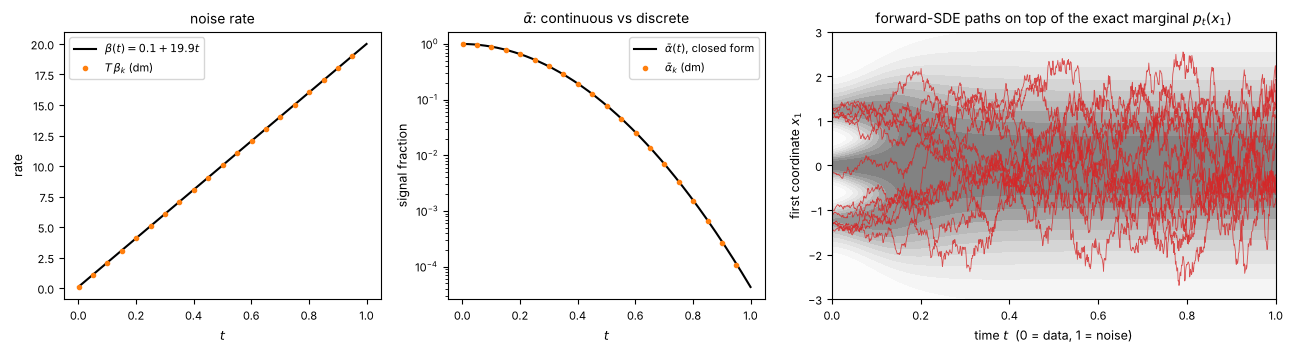

In [5]:
def x1_marginal_density(ts, xs, dist=gmm):
    """Density of the first coordinate of q_t on a (len(xs), len(ts)) grid: a 1-D Gaussian mixture at every t."""
    w, mu, var = dist.weights.numpy(), dist.means[:, 0].numpy(), dist.covs[:, 0, 0].numpy()
    cols = []
    for t in ts:
        ab = abar_fn(t)
        m, v = math.sqrt(ab) * mu, ab * var + (1 - ab)
        cols.append((w * np.exp(-(xs[:, None] - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v)).sum(1))
    return np.stack(cols, 1)


TS_G, XS_G = np.linspace(0, 1, 201), np.linspace(-LIM, LIM, 201)
DENS_TX = x1_marginal_density(TS_G, XS_G)
DENS_TX = (DENS_TX / DENS_TX.max(0, keepdims=True)) ** 0.5   # normalise each time slice; gamma < 1 shows the tails


def show_density_tx(ax):
    """Grey background: p_t(x_1) over (t, x_1), each time slice normalised to its maximum."""
    ax.contourf(TS_G, XS_G, DENS_TX, levels=np.linspace(0, 1, 11), cmap=CMAP_DENSITY)
    ax.set(xlabel="time $t$  (0 = data, 1 = noise)", ylabel="first coordinate $x_1$", xlim=(0, 1), ylim=(-LIM, LIM))


fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
tt = np.linspace(0, 1, 200)
k_show = np.arange(0, T, 50)
axes[0].plot(tt, [beta_fn(t) for t in tt], color="k", label=r"$\beta(t)=0.1+19.9t$")
axes[0].plot((k_show + 1) / T, T * sched.betas.numpy()[k_show], "o", ms=3, color="tab:orange", label=r"$T\,\beta_k$ (dm)")
axes[0].set(xlabel="$t$", ylabel="rate", title="noise rate")
axes[0].legend()
axes[1].semilogy(tt, [abar_fn(t) for t in tt], color="k", label=r"$\bar\alpha(t)$, closed form")
axes[1].semilogy((k_show + 1) / T, AB_DISC[k_show], "o", ms=3, color="tab:orange", label=r"$\bar\alpha_k$ (dm)")
axes[1].set(xlabel="$t$", ylabel="signal fraction", title=r"$\bar\alpha$: continuous vs discrete")
axes[1].legend()
show_density_tx(axes[2])
t_paths = np.linspace(0, 1, fwd_paths.shape[0])
for i in range(fwd_paths.shape[1]):
    axes[2].plot(t_paths, fwd_paths[:, i, 0].numpy(), lw=0.6, color="tab:red", alpha=0.8)
axes[2].set_title(r"forward-SDE paths on top of the exact marginal $p_t(x_1)$")
plt.tight_layout()
plt.show()

The discrete schedule is the continuous one sampled at $t=(k+1)/T$. On the right, each path is jagged, but the cloud of
paths has the marginals $p_t$ (the printed check): the modes of the mixture at $t=0$ melt into a single Gaussian by
$t\approx0.5$. Sampling must undo this, either with the reverse SDE (jagged paths) or with the ODE (smooth paths).

## 2 · Five samplers, one exact score

All samplers below walk down a time grid $1=t_0>t_1>\dots>t_{n-1}=t_{\min}>t_n=0$ and call the noise predictor once per
step. Heun calls it twice, except on the last step. Writing $a_t=\bar\alpha(t)$ and
$\hat x_0=(x_t-\sqrt{1-a_t}\,\hat\epsilon)/\sqrt{a_t}$ (Tweedie), one step from $t$ to $s<t$ is:

| sampler | update $x_t\to x_s$ | NFE / step |
|---|---|---|
| (a) DDPM ancestral | sample $q(x_s\mid x_t,\hat x_0)$: mean $\frac{\sqrt{a_s}(1-a_t/a_s)\hat x_0+\sqrt{a_t/a_s}(1-a_s)x_t}{1-a_t}$, variance $\frac{1-a_s}{1-a_t}(1-\frac{a_t}{a_s})$ | 1 |
| (b) Euler–Maruyama, reverse SDE | $x_t+\big[\tfrac12\beta x_t+\beta\nabla\log p_t\big]h+\sqrt{\beta h}\,z$, with $h=t-s$ | 1 |
| (c) Euler, PF-ODE | $x_t+(s-t)\,v(x_t,t)$, with $v=-\tfrac12\beta(x+\nabla\log p_t)$ | 1 |
| (d) Heun, PF-ODE | predictor $\tilde x=x_t+(s-t)v(x_t,t)$, then $x_t+(s-t)\tfrac12[v(x_t,t)+v(\tilde x,s)]$ | 2 |
| (e) DDIM ($\eta=0$) | $\sqrt{a_s}\,\hat x_0+\sqrt{1-a_s}\,\hat\epsilon$ (derived in §3) | 1 |

(a) is DDPM's posterior step, with $\alpha=a_t/a_s$ for a step that may skip many of the original $T$ steps ("respacing",
Nichol & Dhariwal 2021). No noise is added on the final step: the sampler returns its best guess.

The "network" is the exact noise predictor $\epsilon^*(x,t)=-\sqrt{1-\bar\alpha(t)}\,\nabla\log q_t(x)$ of the mixture,
so that **all differences between samplers are discretisation error**.

In [6]:
def exact_eps_fn(dist, abar=abar_fn):
    """The ideal noise predictor eps*(x, t) = -sqrt(1 - abar(t)) * grad log q_t(x) of a dm.GaussianMixture.

    q_t is the VP-noised mixture (dist.noised), so this is exact at every continuous t > 0."""
    def eps_fn(x, t):
        ab = abar(t)
        return -math.sqrt(1.0 - ab) * dist.noised(ab).score(x)
    return eps_fn


eps_exact = exact_eps_fn(gmm)


def uniform_grid(n_steps):
    """Time grid for n_steps steps: n_steps evaluation times uniform from 1 down to T_MIN, then the final time 0."""
    return np.concatenate([np.linspace(1.0, T_MIN, n_steps), [0.0]])


def _noise(x, gen):
    return torch.randn(x.shape, generator=gen, dtype=x.dtype)


@torch.no_grad()
def ddpm_sampler(eps_fn, x, ts, *, abar=abar_fn, gen=None, return_traj=False):
    """(a) Ancestral sampling on the grid ts: x_s ~ q(x_s | x_t, x0_hat), DDPM's posterior with x0 replaced by x0_hat."""
    traj = [x]
    for t, s in zip(ts[:-1], ts[1:]):
        a_t, a_s = abar(t), abar(s)
        eps = eps_fn(x, t)
        x0 = (x - math.sqrt(1 - a_t) * eps) / math.sqrt(a_t)
        alpha = a_t / a_s                                   # the "alpha" of this possibly large step
        x = (math.sqrt(a_s) * (1 - alpha) * x0 + math.sqrt(alpha) * (1 - a_s) * x) / (1 - a_t)
        if s > 0:                                           # no noise on the last step: return the posterior mean
            x = x + math.sqrt((1 - a_s) / (1 - a_t) * (1 - alpha)) * _noise(x, gen)
        traj.append(x)
    return traj if return_traj else x


@torch.no_grad()
def euler_maruyama_sampler(eps_fn, x, ts, *, gen=None, return_traj=False):
    """(b) Euler–Maruyama on the reverse-time VP-SDE dx = [-beta x / 2 - beta * score] dt + sqrt(beta) dW, dt < 0."""
    traj = [x]
    for t, s in zip(ts[:-1], ts[1:]):
        h, b = t - s, beta_fn(t)                            # h > 0: we step backwards in time
        score = -eps_fn(x, t) / math.sqrt(1 - abar_fn(t))
        x = x + (0.5 * b * x + b * score) * h
        if s > 0:
            x = x + math.sqrt(b * h) * _noise(x, gen)
        traj.append(x)
    return traj if return_traj else x


def pf_ode_velocity(eps_fn, x, t):
    """dx/dt of the probability-flow ODE: -beta(t)/2 * (x + score), with score = -eps / sqrt(1 - abar)."""
    return -0.5 * beta_fn(t) * (x - eps_fn(x, t) / math.sqrt(1 - abar_fn(t)))


@torch.no_grad()
def euler_ode_sampler(eps_fn, x, ts, *, gen=None, return_traj=False):
    """(c) Euler's method on the probability-flow ODE, in the original variables (x, t)."""
    traj = [x]
    for t, s in zip(ts[:-1], ts[1:]):
        x = x + (s - t) * pf_ode_velocity(eps_fn, x, t)
        traj.append(x)
    return traj if return_traj else x


@torch.no_grad()
def heun_ode_sampler(eps_fn, x, ts, *, gen=None, return_traj=False):
    """(d) Heun's method (explicit trapezoidal rule, 2nd order) on the probability-flow ODE.

    The last step (to t = 0, where the network was never trained) is a plain Euler step: 2 * steps - 1 NFE."""
    traj = [x]
    for t, s in zip(ts[:-1], ts[1:]):
        v = pf_ode_velocity(eps_fn, x, t)
        x_pred = x + (s - t) * v
        x = x + (s - t) * 0.5 * (v + pf_ode_velocity(eps_fn, x_pred, s)) if s > 0 else x_pred
        traj.append(x)
    return traj if return_traj else x


@torch.no_grad()
def ddim_sampler(eps_fn, x, ts, *, eta=0.0, abar=abar_fn, gen=None, return_traj=False):
    """(e) DDIM (Song, Meng & Ermon 2021). eta = 0: deterministic; eta = 1: DDPM's ancestral sampler."""
    traj = [x]
    for t, s in zip(ts[:-1], ts[1:]):
        a_t, a_s = abar(t), abar(s)
        eps = eps_fn(x, t)
        x0 = (x - math.sqrt(1 - a_t) * eps) / math.sqrt(a_t)
        gamma = eta * math.sqrt((1 - a_s) / (1 - a_t) * (1 - a_t / a_s))     # std of the fresh noise
        x = math.sqrt(a_s) * x0 + math.sqrt(max(1 - a_s - gamma ** 2, 0.0)) * eps
        if gamma > 0 and s > 0:
            x = x + gamma * _noise(x, gen)
        traj.append(x)
    return traj if return_traj else x


SAMPLERS = {  # name: (function, uses Heun's 2 NFE per step?, stochastic?)
    "DDPM ancestral": (ddpm_sampler, False, True),
    "Euler–Maruyama SDE": (euler_maruyama_sampler, False, True),
    "Euler ODE": (euler_ode_sampler, False, False),
    "Heun ODE": (heun_ode_sampler, True, False),
    "DDIM": (ddim_sampler, False, False),
}

**CHECK against `dmtools`.** `dm.ddpm_sample` (notebook 02) runs the full 1000-step chain with the discrete schedule.
Our sampler must reproduce it exactly when given the same grid, the same $\bar\alpha_k$ and the same random numbers. To
hand the exact score to `dmtools` we wrap it as a model with the usual signature `model(x, t, y=None)`.

In [7]:
class ExactEpsModel:
    """dmtools-style model(x, t, y=None) returning the exact eps at integer timesteps t of a dm.NoiseSchedule."""

    def __init__(self, dist, schedule):
        self.dist, self.ab = dist, schedule.alpha_bars.double().cpu()

    def __call__(self, x, t, y=None):
        assert (t == t[0]).all(), "the dmtools samplers use one timestep per batch"
        ab = float(self.ab[int(t[0])])
        return (-math.sqrt(1 - ab) * self.dist.noised(ab).score(x.double().cpu())).to(x.device, x.dtype)


def abar_disc(t):
    """dm.NoiseSchedule's alpha_bar_k at the continuous time t = (k+1)/T, and 1 at t = 0."""
    return 1.0 if t == 0 else float(AB_DISC[int(round(t * T)) - 1])


def disc_grid(n_steps):
    """The times (k+1)/T of the timesteps dm.ddim_sample picks for n_steps (descending), followed by 0."""
    ks = np.unique(np.linspace(0, T - 1, n_steps).round().astype(int))[::-1]
    return np.concatenate([(ks + 1) / T, [0.0]])


exact_model = ExactEpsModel(gmm, sched)
eps_disc = exact_eps_fn(gmm, abar=abar_disc)
x_chk = torch.randn(300, 2, generator=torch.Generator().manual_seed(5))           # float32, like dmtools
ours = ddpm_sampler(eps_disc, x_chk, disc_grid(T), abar=abar_disc, gen=torch.Generator().manual_seed(6))
theirs = dm.ddpm_sample(exact_model, sched, x_chk.shape, x_T=x_chk, generator=torch.Generator().manual_seed(6))
print(f"CHECK ddpm_sampler == dm.ddpm_sample (1000 steps): max |diff| = {(ours - theirs).abs().max():.1e}")
assert torch.allclose(ours, theirs, atol=1e-3)

CHECK ddpm_sampler == dm.ddpm_sample (1000 steps): max |diff| = 3.2e-05


### 2.1 Quality vs NFE

Every sampler starts from the **same** noise $x_T\sim\mathcal N(0,I)$. $\mathcal N(0,I)$ is not exactly $q_1$, but here
$\bar\alpha(1)\approx4\cdot10^{-5}$, so the mismatch is negligible. A stochastic sampler produces a fresh random sample
set on every run, so its metrics fluctuate by about the width of the floor band. We therefore average them over three
seeds. Heun's NFE is $2n-1$ for $n$ steps, so its budgets land one below the nominal value.

For the deterministic samplers we also record the state at $t_{\min}$ for the first `N_PATH` particles. We compare it with
a **reference solution** of the same ODE from the same $x_T$ (Heun with thousands of steps). The resulting **pathwise
error** measures the discretisation error directly, without the finite-sample floor of a distribution metric.

In [8]:
def steps_for_nfe(name, nfe):
    """Number of steps a sampler can afford with `nfe` network evaluations, and the NFE it actually uses."""
    if SAMPLERS[name][1]:              # Heun: n steps cost 2n - 1 NFE
        n = (nfe + 1) // 2
        return n, 2 * n - 1
    return nfe, nfe


def nfe_sweep(eps_fn, x_T, names, nfes, x_ref=None, n_seeds=3):
    """Run each sampler at each NFE budget. Returns {name: list of dicts(nfe, mmd, sw, path)}.

    Stochastic samplers: metrics averaged over n_seeds noise seeds. Deterministic ones: also the pathwise error at
    t_min (before the final jump to t = 0) against the reference solution x_ref."""
    results = {name: [] for name in names}
    for name in names:
        fn, _, stochastic = SAMPLERS[name]
        for nfe in nfes:
            n, used = steps_for_nfe(name, nfe)
            metrics, path = [], None
            for seed in range(n_seeds if stochastic else 1):
                traj = fn(eps_fn, x_T, uniform_grid(n), gen=torch.Generator().manual_seed(seed), return_traj=True)
                metrics.append(quality(traj[-1]))
            if x_ref is not None and not stochastic:
                path = (traj[-2][:N_PATH] - x_ref).norm(dim=1).mean().item()
            mmd, sw = np.mean(metrics, axis=0)
            results[name].append(dict(nfe=used, mmd=mmd, sw=sw, path=path))
    return results


x_T = torch.randn(N_EVAL, 2, generator=torch.Generator().manual_seed(0), dtype=torch.float64)
t0 = time.time()
x_ref_tmin = heun_ode_sampler(eps_exact, x_T[:N_PATH], uniform_grid(REF_STEPS), return_traj=True)[-2]
print(f"reference ODE solution: {2 * REF_STEPS - 1} NFE on {N_PATH} particles in {time.time() - t0:.0f} s")
t0 = time.time()
sweep = nfe_sweep(eps_exact, x_T, list(SAMPLERS), NFES, x_ref=x_ref_tmin)
print(f"sweep: {len(SAMPLERS)} samplers x {len(NFES)} budgets in {time.time() - t0:.0f} s\n")
print(f"{'sampler':20s} " + " ".join(f"{n:>7d}" for n in NFES) + "   <- nominal NFE; MMD^2 x 1e3")
for name, rows in sweep.items():
    print(f"{name:20s} " + " ".join(f"{1e3 * r['mmd']:7.2f}" for r in rows))
print(f"{'floor':20s} {1e3 * floor[:, 0].mean():7.2f}")

reference ODE solution: 7999 NFE on 500 particles in 7 s


sweep: 5 samplers x 7 budgets in 80 s

sampler                    5      10      20      50     100     250    1000   <- nominal NFE; MMD^2 x 1e3
DDPM ancestral        367.40   55.78   34.46   16.57   10.87    9.51    9.50
Euler–Maruyama SDE    172.46  134.26   41.04    9.89    7.74    7.99    9.53
Euler ODE             127.90   22.98   10.81    8.75    8.30    8.09    8.00
Heun ODE               34.02   74.31   17.91    7.98    7.86    7.95    7.98
DDIM                  308.45   34.11   18.96   10.48    8.82    8.23    8.03
floor                   8.18


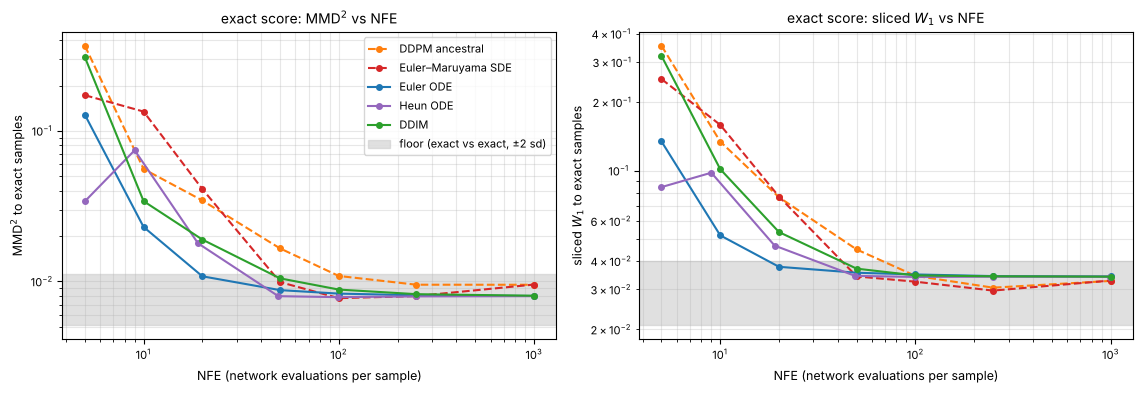

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, (j, key, label) in zip(axes, [(0, "mmd", "MMD$^2$ to exact samples"), (1, "sw", "sliced $W_1$ to exact samples")]):
    for name, rows in sweep.items():
        ls = "--" if SAMPLERS[name][2] else "-"   # dashed = stochastic
        ax.loglog([r["nfe"] for r in rows], [r[key] for r in rows], "o" + ls, color=COL[name], ms=4, label=name)
    lo, hi = floor[:, j].mean() - 2 * floor[:, j].std(), floor[:, j].mean() + 2 * floor[:, j].std()
    ax.axhspan(max(lo, 1e-6), hi, color=COL["floor"], alpha=0.6, label="floor (exact vs exact, ±2 sd)")
    ax.set(xlabel="NFE (network evaluations per sample)", ylabel=label, title=f"exact score: {label.split(' to')[0]} vs NFE")
    ax.grid(alpha=0.3, which="both")
axes[0].legend()
plt.tight_layout()
plt.show()

Reading the figure (the solid lines are deterministic, the dashed ones stochastic):

* **At small budgets the deterministic samplers win by a wide margin.** With tens of NFE the ODE solvers are already near
  the floor, while DDPM and Euler–Maruyama are still clearly off. A stochastic sampler must integrate the injected noise
  as well as the drift, and with big steps the noise it adds is badly calibrated.
* **Given enough steps, everything converges** to the floor, because all five samplers discretise equations with the same
  marginals. The stochastic samplers only get there at hundreds of NFE. This is why DDPM needed $T=1000$. (The
  deterministic curves converge to one fixed sample set, the image of $x_T$ under the exact ODE map. That set is itself
  one random draw, which is why they settle at one particular point inside the floor band.)
* **Higher order is not automatically better at very low NFE.** With a handful of steps, Heun's corrector evaluates the
  field at a poor predicted point, and its ranking at the smallest budgets jumps around: it can do worse than Euler.
  Its second-order accuracy only pays off once the steps are small. The next figure makes this precise.

The distribution metrics saturate at the floor, so they cannot show the *rate* at which each solver converges. The
pathwise error can:

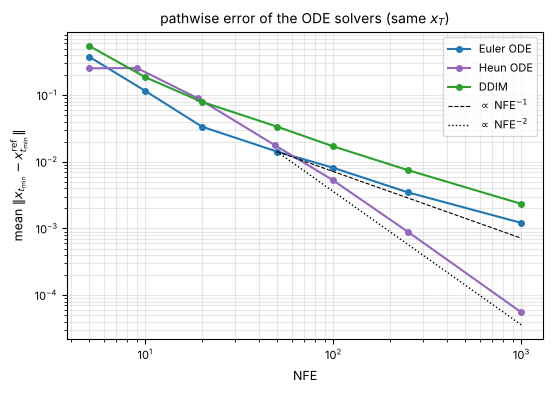

fitted order of convergence (slope over the three largest budgets): Euler ODE 0.82, Heun ODE 1.98, DDIM 0.86


In [10]:
fig, ax = plt.subplots(figsize=(5.6, 4))
slopes = {}
for name in ["Euler ODE", "Heun ODE", "DDIM"]:
    nfe = np.array([r["nfe"] for r in sweep[name]])
    err = np.array([r["path"] for r in sweep[name]])
    ax.loglog(nfe, err, "o-", color=COL[name], ms=4, label=name)
    slopes[name] = -np.polyfit(np.log(nfe[-3:]), np.log(err[-3:]), 1)[0]   # fitted order over the 3 largest budgets
n_guide = np.array([50, 1000])
e_mid = sweep["Euler ODE"][3]["path"]
ax.loglog(n_guide, e_mid * (n_guide / 50.0) ** -1, "k--", lw=0.8, label=r"$\propto$ NFE$^{-1}$")
ax.loglog(n_guide, e_mid * (n_guide / 50.0) ** -2, "k:", lw=1.0, label=r"$\propto$ NFE$^{-2}$")
ax.set(xlabel="NFE", ylabel=r"mean $\|x_{t_{\min}}-x^{\rm ref}_{t_{\min}}\|$",
       title="pathwise error of the ODE solvers (same $x_T$)")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()
print("fitted order of convergence (slope over the three largest budgets): "
      + ", ".join(f"{k} {v:.2f}" for k, v in slopes.items()))
if not FAST:
    assert 0.7 < slopes["Euler ODE"] < 1.3 and 0.7 < slopes["DDIM"] < 1.3 and 1.6 < slopes["Heun ODE"] < 2.4

This is the textbook picture. Euler and DDIM are **first-order** methods (halving the step halves the error) and Heun is
**second-order** (halving the step quarters it), which is why it ends up orders of magnitude more accurate at the same
NFE. At small NFE all solvers are outside this asymptotic regime, which is where *where you put the steps* (§6) and
*which variables you integrate in* (§3) matter most.

Notice also that on this toy, DDIM is **not** more accurate than plain Euler in $(x,t)$. That seems at odds with DDIM's
reputation as "the" fast sampler. §3 explains both the reputation and the exception.

## 3 · DDIM: a non-Markovian forward process, and Euler in disguise

### 3.1 Derivation

The DDPM loss only ever looks at the marginals $q(x_t\mid x_0)=\mathcal N(\sqrt{a_t}\,x_0,(1-a_t)I)$, not at how the
chain gets from one $t$ to the next. Song, Meng & Ermon (2021) exploited this: *any* process with these marginals is
served by the same trained $\hat\epsilon$. They propose the family of reverse kernels (for $s<t$)

$$q_\gamma(x_s\mid x_t,x_0)=\mathcal N\!\Big(\sqrt{a_s}\,x_0+\sqrt{1-a_s-\gamma_t^2}\;\frac{x_t-\sqrt{a_t}\,x_0}{\sqrt{1-a_t}},\ \gamma_t^2I\Big).$$

**The marginals are preserved, by induction.** If $x_t=\sqrt{a_t}x_0+\sqrt{1-a_t}\,\epsilon$, then the fraction above
is just $\epsilon$, so $x_s=\sqrt{a_s}x_0+\sqrt{1-a_s-\gamma_t^2}\,\epsilon+\gamma_t z$. This is Gaussian with mean
$\sqrt{a_s}x_0$ and variance $(1-a_s-\gamma_t^2)+\gamma_t^2=1-a_s$, which is exactly $q(x_s\mid x_0)$, for **every**
$\gamma_t$. Plugging in the network's guesses $\hat x_0,\hat\epsilon$ gives the **DDIM update**

$$\boxed{\;x_s=\sqrt{a_s}\,\hat x_0+\sqrt{1-a_s-\gamma_t^2}\;\hat\epsilon+\gamma_t z,\qquad
\gamma_t=\eta\sqrt{\tfrac{1-a_s}{1-a_t}}\sqrt{1-\tfrac{a_t}{a_s}}\;}$$

(Song et al. call the noise standard deviation $\sigma_t$; we write $\gamma_t$, because $\sigma$ will denote the noise *level* in §3.2.)

* $\eta=1$ makes $\gamma_t^2$ the DDPM posterior variance, and the kernel becomes DDPM's $q(x_s\mid x_t,x_0)$: ancestral sampling.
* $\eta=0$ is **deterministic**: "re-noise the clean guess with the *predicted* noise, to the next noise level".
  Nothing in the derivation required $s=t-1$, so the steps can be large.

Three numerical checks: the marginal claim (Monte Carlo), our sampler against `dm.ddim_sample`, and $\eta=1$ against
our DDPM sampler.

In [11]:
# CHECK 1: the non-Markovian kernel leaves q(x_s | x_0) = N(sqrt(a_s) x0, (1 - a_s) I) intact, whatever sigma
g = torch.Generator().manual_seed(7)
N_MC = 20_000 if FAST else 200_000
x0_mc = gmm.sample(N_MC, generator=g).double()
a_t, a_s = abar_fn(0.5), abar_fn(0.3)
x_t_mc = math.sqrt(a_t) * x0_mc + math.sqrt(1 - a_t) * torch.randn(N_MC, 2, generator=g, dtype=torch.float64)
print(f"CHECK 1: residual r = x_s - sqrt(a_s) x0 should have mean 0, variance 1 - a_s = {1 - a_s:.4f}, cov(r, x0) = 0, for any gamma")
for eta in (0.0, 0.5, 1.0):
    gamma = eta * math.sqrt((1 - a_s) / (1 - a_t) * (1 - a_t / a_s))
    eps_implied = (x_t_mc - math.sqrt(a_t) * x0_mc) / math.sqrt(1 - a_t)
    x_s_mc = math.sqrt(a_s) * x0_mc + math.sqrt(1 - a_s - gamma ** 2) * eps_implied \
        + gamma * torch.randn(N_MC, 2, generator=g, dtype=torch.float64)
    r = x_s_mc - math.sqrt(a_s) * x0_mc
    cov_rx = ((r - r.mean(0)) * (x0_mc - x0_mc.mean(0))).mean(0)
    print(f"  eta = {eta}: mean {r.mean(0).numpy().round(4)}, var {r.var(0).numpy().round(4)}, "
          f"cov(r, x0) {cov_rx.numpy().round(4)}")
    assert torch.allclose(r.var(0), torch.full((2,), 1 - a_s, dtype=torch.float64), atol=0.02)

# CHECK 2: our DDIM reproduces dm.ddim_sample on the discrete schedule
for n in (10, 50):
    ours = ddim_sampler(eps_disc, x_chk, disc_grid(n), abar=abar_disc)
    theirs = dm.ddim_sample(exact_model, sched, x_chk.shape, n_steps=n, x_T=x_chk)
    print(f"CHECK 2: ddim_sampler == dm.ddim_sample ({n} steps): max |diff| = {(ours - theirs).abs().max():.1e}")
    assert torch.allclose(ours, theirs, atol=1e-4)

# CHECK 3: DDIM with eta = 1 is exactly DDPM ancestral sampling (same grid, same random numbers)
ours_ddim = ddim_sampler(eps_exact, x_T[:300], uniform_grid(20), eta=1.0, gen=torch.Generator().manual_seed(8))
ours_ddpm = ddpm_sampler(eps_exact, x_T[:300], uniform_grid(20), gen=torch.Generator().manual_seed(8))
print(f"CHECK 3: DDIM(eta=1) == DDPM ancestral (20 steps): max |diff| = {(ours_ddim - ours_ddpm).abs().max():.1e}")
assert torch.allclose(ours_ddim, ours_ddpm, atol=1e-9)

CHECK 1: residual r = x_s - sqrt(a_s) x0 should have mean 0, variance 1 - a_s = 0.6037, cov(r, x0) = 0, for any gamma
  eta = 0.0: mean [-0.0014 -0.0023], var [0.6041 0.6042], cov(r, x0) [-0.0006 -0.0002]
  eta = 0.5: mean [-0.001  -0.0018], var [0.606  0.6048], cov(r, x0) [-0.0006 -0.0006]
  eta = 1.0: mean [ 0.0031 -0.0019], var [0.6037 0.6057], cov(r, x0) [-0.0003 -0.0003]
CHECK 2: ddim_sampler == dm.ddim_sample (10 steps): max |diff| = 9.5e-07


CHECK 2: ddim_sampler == dm.ddim_sample (50 steps): max |diff| = 1.0e-05
CHECK 3: DDIM(eta=1) == DDPM ancestral (20 steps): max |diff| = 1.3e-14


### 3.2 DDIM is Euler's method in the variables $\tilde x=x/\sqrt{\bar\alpha}$ and $\sigma=\sqrt{(1-\bar\alpha)/\bar\alpha}$

Divide the forward process by $\sqrt{a_t}$: $\ \tilde x_t:=x_t/\sqrt{a_t}=x_0+\sigma_t\,\epsilon$. In these coordinates
the VP process becomes the **variance-exploding** process of notebook 01, with noise level $\sigma$ (Karras et al. 2022).
Its probability-flow ODE (the same derivation as §1.2 with $f=0$, $g^2=d\sigma^2/dt$) is

$$\frac{d\tilde x}{d\sigma}=-\sigma\,\nabla_{\tilde x}\log p_\sigma(\tilde x)=\hat\epsilon=\frac{\tilde x-D(\tilde x;\sigma)}{\sigma},
\qquad D(\tilde x;\sigma)=\hat x_0 \text{ (the posterior-mean denoiser).}$$

Now divide the DDIM update ($\eta=0$) by $\sqrt{a_s}$, and use $\hat x_0=\tilde x_t-\sigma_t\hat\epsilon$:

$$\tilde x_s=\hat x_0+\sigma_s\hat\epsilon=\tilde x_t+(\sigma_s-\sigma_t)\,\hat\epsilon(\tilde x_t,\sigma_t).$$

That is **one Euler step of $d\tilde x/d\sigma=\hat\epsilon$**. The same equation, rearranged, gives the most useful way to
picture a DDIM step:

$$\boxed{\;\tilde x_s=\frac{\sigma_s}{\sigma_t}\,\tilde x_t+\Big(1-\frac{\sigma_s}{\sigma_t}\Big)\,\hat x_0\;}$$

*Move the fraction $1-\sigma_s/\sigma_t$ of the way from where you are to where the denoiser thinks the data is.*
Two consequences follow, and we check each below.

1. **It is exact whenever $\hat x_0$ is constant along the step.** The exact trajectory is then the straight line
   $\tilde x(\sigma)=\hat x_0+\sigma\hat\epsilon$, and Euler is exact on straight lines.
2. **It can never overshoot.** For any step size it is a convex combination of the current point and the denoised guess.
   Euler or Heun in $(x,t)$ have no such guarantee.

In [12]:
def sigma_fn(t):
    """EDM noise level sigma(t) = sqrt((1 - abar) / abar) of the VP process at time t."""
    return math.sqrt(1.0 / abar_fn(t) - 1.0)


def t_of_sigma(sig):
    """Inverse of sigma_fn: solve BETA_MIN t + (BETA_MAX - BETA_MIN) t^2 / 2 = log(1 + sigma^2) for t."""
    L = math.log1p(sig * sig)
    return (-BETA_MIN + math.sqrt(BETA_MIN ** 2 + 2 * (BETA_MAX - BETA_MIN) * L)) / (BETA_MAX - BETA_MIN)


SIGMA_MAX, SIGMA_MIN = sigma_fn(1.0), sigma_fn(T_MIN)
print(f"sigma ranges from {SIGMA_MAX:.1f} (t = 1) down to {SIGMA_MIN:.4f} (t = t_min);  "
      f"round trip t -> sigma -> t error {abs(t_of_sigma(sigma_fn(0.37)) - 0.37):.1e}")


def sigmas_of_times(ts):
    return np.array([sigma_fn(t) if t > 0 else 0.0 for t in ts])


@torch.no_grad()
def euler_sigma_sampler(eps_fn, x, sigmas, *, return_traj=False):
    """Euler on d x~/d sigma = eps_hat in the variables x~ = x / sqrt(abar) (= x * sqrt(1 + sigma^2)). Input/output in VP units."""
    xt = x * math.sqrt(1 + sigmas[0] ** 2)
    traj = [x]
    for s_t, s_s in zip(sigmas[:-1], sigmas[1:]):
        eps = eps_fn(xt / math.sqrt(1 + s_t ** 2), t_of_sigma(s_t))   # the eps-network sees the VP-scaled input
        xt = xt + (s_s - s_t) * eps
        traj.append(xt / math.sqrt(1 + s_s ** 2))
    return traj if return_traj else traj[-1]


# CHECK 4: DDIM (eta = 0) and Euler in (x~, sigma) are the same algorithm
for n in (5, 50):
    a = ddim_sampler(eps_exact, x_T, uniform_grid(n))
    b = euler_sigma_sampler(eps_exact, x_T, sigmas_of_times(uniform_grid(n)))
    print(f"CHECK 4: DDIM == Euler in (x~, sigma), {n} steps: max |diff| = {(a - b).abs().max():.1e}")
    assert torch.allclose(a, b, atol=1e-9)

sigma ranges from 152.2 (t = 1) down to 0.0105 (t = t_min);  round trip t -> sigma -> t error 0.0e+00
CHECK 4: DDIM == Euler in (x~, sigma), 5 steps: max |diff| = 8.4e-15


CHECK 4: DDIM == Euler in (x~, sigma), 50 steps: max |diff| = 7.3e-14


**Consequence 1: straight lines.** We follow a dozen exact ODE trajectories (DDIM with 400 log-spaced steps) and record
$\tilde x$ and the denoiser output $\hat x_0$ along the way.

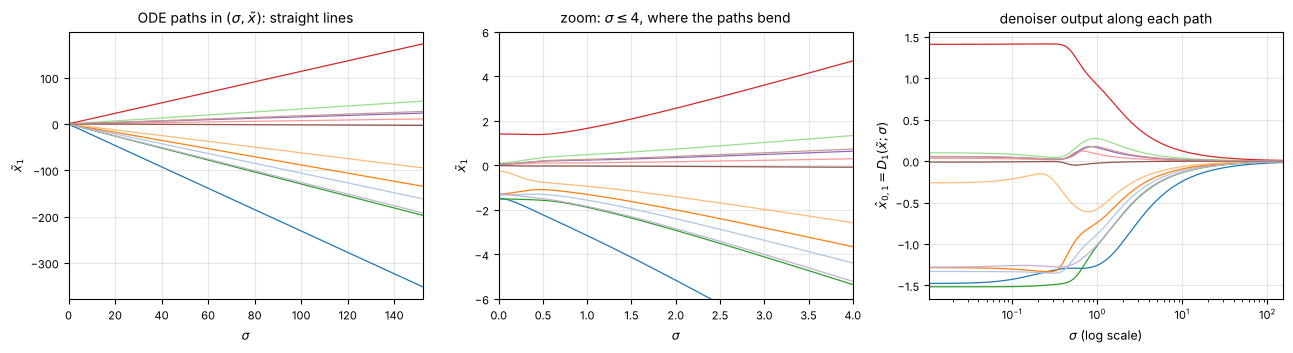

In [13]:
N_LINES = 12
sig_fine = np.exp(np.linspace(math.log(SIGMA_MAX), math.log(SIGMA_MIN), 400))
xt = x_T[:N_LINES] * math.sqrt(1 + SIGMA_MAX ** 2)
rec_xt, rec_x0 = [], []
for s_t, s_s in zip(sig_fine[:-1], sig_fine[1:]):
    eps = eps_exact(xt / math.sqrt(1 + s_t ** 2), t_of_sigma(s_t))
    rec_xt.append(xt.clone())
    rec_x0.append(xt - s_t * eps)                    # D(x~; sigma) = x0_hat
    xt = xt + (s_s - s_t) * eps
rec_xt, rec_x0, sig_rec = torch.stack(rec_xt), torch.stack(rec_x0), sig_fine[:-1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cols = plt.get_cmap("tab20")(np.arange(N_LINES))
for i in range(N_LINES):
    axes[0].plot(sig_rec, rec_xt[:, i, 0], color=cols[i], lw=0.9)
    axes[1].plot(sig_rec, rec_xt[:, i, 0], color=cols[i], lw=0.9)
    axes[2].semilogx(sig_rec, rec_x0[:, i, 0], color=cols[i], lw=0.9)
axes[0].set(xlabel=r"$\sigma$", ylabel=r"$\tilde x_1$", title=r"ODE paths in $(\sigma,\tilde x)$: straight lines", xlim=(0, SIGMA_MAX))
axes[1].set(xlabel=r"$\sigma$", ylabel=r"$\tilde x_1$", title=r"zoom: $\sigma\leq 4$, where the paths bend", xlim=(0, 4), ylim=(-6, 6))
axes[2].set(xlabel=r"$\sigma$ (log scale)", ylabel=r"$\hat x_{0,1}=D_1(\tilde x;\sigma)$",
            title=r"denoiser output along each path", xlim=(SIGMA_MIN, SIGMA_MAX))
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Over almost the whole range of $\sigma$ the paths are straight lines (left). When $\sigma$ is much larger than the data,
the noisy point carries little information about which mode it came from, so $\hat x_0$ sits near the data mean and
barely moves (right). All the bending happens in the window where $\sigma$ is comparable to the structure of the data
(here roughly $0.1\lesssim\sigma\lesssim3$). There $\hat x_0$ commits to a mode and then to a point within it. DDIM's
error comes only from that window. §6 measures this directly and asks where the steps should go.

**Consequence 2: stability.** The cleanest test is one-dimensional Gaussian data $x_0\sim\mathcal N(0,\lambda)$. Every
quantity is then available in closed form: $\hat\epsilon(x,t)=\sqrt{1-a_t}\,x/(\lambda a_t+1-a_t)$, and the exact ODE maps
$x_T=1$ to $\sqrt\lambda/\sqrt{\lambda a_1+1-a_1}$. Since the ODE is linear, the sampler's output from $x_T=1$ *is* the
standard deviation of the distribution it generates. We vary the data variance $\lambda$ over seven orders of magnitude.

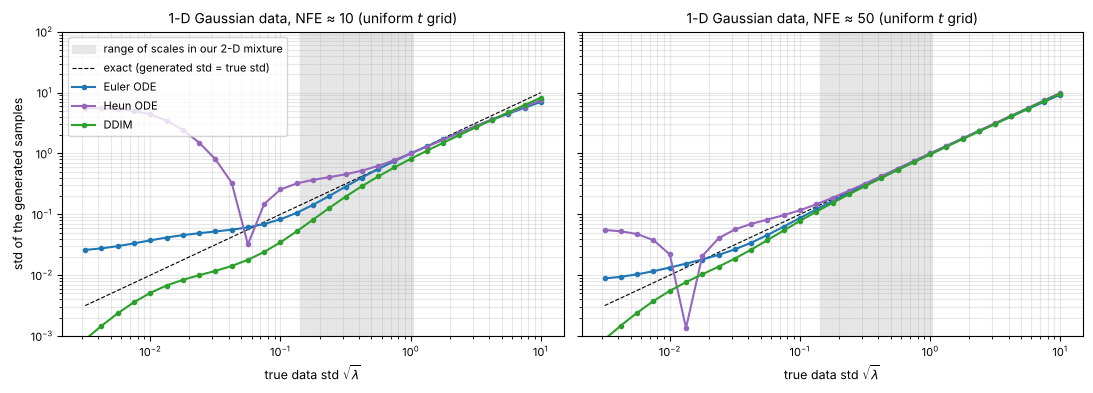

NFE 10, smallest variance (lambda = 1e-05): generated/true std  Euler ODE 8.2, Heun ODE 1.8e+03, DDIM 0.28
NFE 50, smallest variance (lambda = 1e-05): generated/true std  Euler ODE 2.8, Heun ODE 17, DDIM 0.28


In [14]:
def gaussian_eps_fn(lam):
    """Exact noise predictor for 1-D data x0 ~ N(0, lam): q_t = N(0, lam * abar + 1 - abar)."""
    def eps_fn(x, t):
        ab = abar_fn(t)
        return math.sqrt(1 - ab) * x / (lam * ab + 1 - ab)
    return eps_fn


lams = np.logspace(-5, 2, 29)
one = torch.ones(1, 1, dtype=torch.float64)
true_std = np.sqrt(lams) / np.sqrt(lams * abar_fn(1.0) + 1 - abar_fn(1.0))
gen_std = {}
for nfe in (10, 50):
    for name in ["Euler ODE", "Heun ODE", "DDIM"]:
        n, _ = steps_for_nfe(name, nfe)
        out = [SAMPLERS[name][0](gaussian_eps_fn(lam), one, uniform_grid(n)).abs().item() for lam in lams]
        gen_std[(name, nfe)] = np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
toy_band = (math.sqrt(gmm.covs.diagonal(dim1=1, dim2=2).min().item()), math.sqrt(x_true.var(0).max().item()))
for ax, nfe in zip(axes, (10, 50)):
    ax.axvspan(*toy_band, color="0.9", label="range of scales in our 2-D mixture")
    ax.loglog(true_std, true_std, "k--", lw=0.8, label="exact (generated std = true std)")
    for name in ["Euler ODE", "Heun ODE", "DDIM"]:
        ax.loglog(true_std, gen_std[(name, nfe)], "o-", ms=3, color=COL[name], label=name)
    ax.set(xlabel=r"true data std $\sqrt{\lambda}$", title=f"1-D Gaussian data, NFE ≈ {nfe} (uniform $t$ grid)",
           ylim=(1e-3, 1e2))
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("std of the generated samples")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()
for nfe in (10, 50):
    print(f"NFE {nfe}, smallest variance (lambda = {lams[0]:.0e}): generated/true std  "
          + ", ".join(f"{name} {gen_std[(name, nfe)][0] / true_std[0]:.2g}" for name in ["Euler ODE", "Heun ODE", "DDIM"]))

* **DDIM never overshoots.** Its generated std is never larger than the truth, because each step is a convex combination
  of $\tilde x$ and $\hat x_0$. For Gaussian data one can show that every step contracts slightly *more* than the exact
  flow. Its errors are on the side of too little spread: for tiny $\lambda$ the final step returns the posterior mean
  $\hat x_0$, which suppresses fluctuations smaller than $\sigma_{\min}$. These errors are always small in absolute
  terms, since the generated std never exceeds the true one.
* **Euler and Heun in $(x,t)$ are exact for $\lambda=1$**: unit-variance Gaussian data is a fixed point of the VP process,
  so the ODE does nothing. Away from $\lambda=1$ the ODE becomes **stiff** near $t\to0$ for small $\lambda$: its
  right-hand side contains $1/(\lambda a_t+1-a_t)$, which explodes. Explicit Euler then contracts too little and leaves
  *residual noise* many times the true std. Heun's corrector overshoots, its output oscillates in sign (the V-shaped dips
  are where it happens to cross zero), and it can blow up completely. Adding steps helps only slowly, because the step
  must be small compared with the fastest time scale of the ODE, which is set by the smallest data variance. This is a
  stiffness problem, and a higher order does not cure it.

This explains the §2 result. Our 2-D mixture lives in the shaded band, where all three are stable and Euler-in-$t$ is
slightly more accurate. Real data is different. Images have a few high-variance directions and a vast number of
directions with tiny variance (fine textures, pixel-level detail). There Euler-in-$t$ leaves visible grain, and DDIM's
robustness is decisive (try it in Exercise 2). The same convex-combination structure is why DDIM keeps working with
10–50 large steps, and it is the starting point of the "exponential integrator" family of fast solvers (DPM-Solver,
Lu et al. 2022). Those integrate the linear part exactly and only approximate how $\hat x_0$ changes.

## 4 · Trajectories: smooth ODE paths, jagged SDE paths

Same starting noise, two samplers: the ODE (DDIM, 200 steps) and the reverse SDE (DDPM ancestral, 1000 steps). We keep
the full trajectories and check two claims from §1. First, the marginals agree at intermediate times. Second, the ODE
is a deterministic map while the SDE is not.

In [15]:
N_TRAJ = 1000 if FAST else 2000
x_T_traj = torch.randn(N_TRAJ, 2, generator=torch.Generator().manual_seed(21), dtype=torch.float64)
grid_ode, grid_sde = uniform_grid(200), uniform_grid(1000)
ode_traj = torch.stack(ddim_sampler(eps_exact, x_T_traj, grid_ode, return_traj=True))
sde_traj = torch.stack(ddpm_sampler(eps_exact, x_T_traj, grid_sde, gen=torch.Generator().manual_seed(22),
                                    return_traj=True))

# CHECK: determinism. Re-running the ODE reproduces it bit for bit; a new seed sends SDE particles elsewhere.
ode_again = ddim_sampler(eps_exact, x_T_traj, grid_ode)
sde_again = ddpm_sampler(eps_exact, x_T_traj, grid_sde, gen=torch.Generator().manual_seed(23))
print(f"ODE re-run:          max |diff| = {(ode_again - ode_traj[-1]).abs().max():.1e}")
print(f"SDE with a new seed: mean |diff| = {(sde_again - sde_traj[-1]).norm(dim=1).mean():.2f}  (same x_T!)")

# CHECK: both have the exact marginals q_t at intermediate times (sliced W1 to fresh exact samples of q_t)
print("sliced W1 to exact samples of q_t:")
for t_chk in (0.5, 0.2, 0.05):
    i_o, i_s = np.abs(grid_ode - t_chk).argmin(), np.abs(grid_sde - t_chk).argmin()
    q_t = gmm.noised(abar_fn(grid_ode[i_o]))
    ref_t = q_t.sample(N_TRAJ, generator=torch.Generator().manual_seed(24))
    fl_t = dm.sliced_wasserstein(q_t.sample(N_TRAJ, generator=torch.Generator().manual_seed(25)), ref_t)
    print(f"  t = {t_chk}:  ODE {dm.sliced_wasserstein(ode_traj[i_o], ref_t):.4f}   "
          f"SDE {dm.sliced_wasserstein(sde_traj[i_s], ref_t):.4f}   exact vs exact {fl_t:.4f}")

ODE re-run:          max |diff| = 0.0e+00
SDE with a new seed: mean |diff| = 1.84  (same x_T!)
sliced W1 to exact samples of q_t:


  t = 0.5:  ODE 0.0374   SDE 0.0411   exact vs exact 0.0282


  t = 0.2:  ODE 0.0306   SDE 0.0328   exact vs exact 0.0322


  t = 0.05:  ODE 0.0307   SDE 0.0430   exact vs exact 0.0334


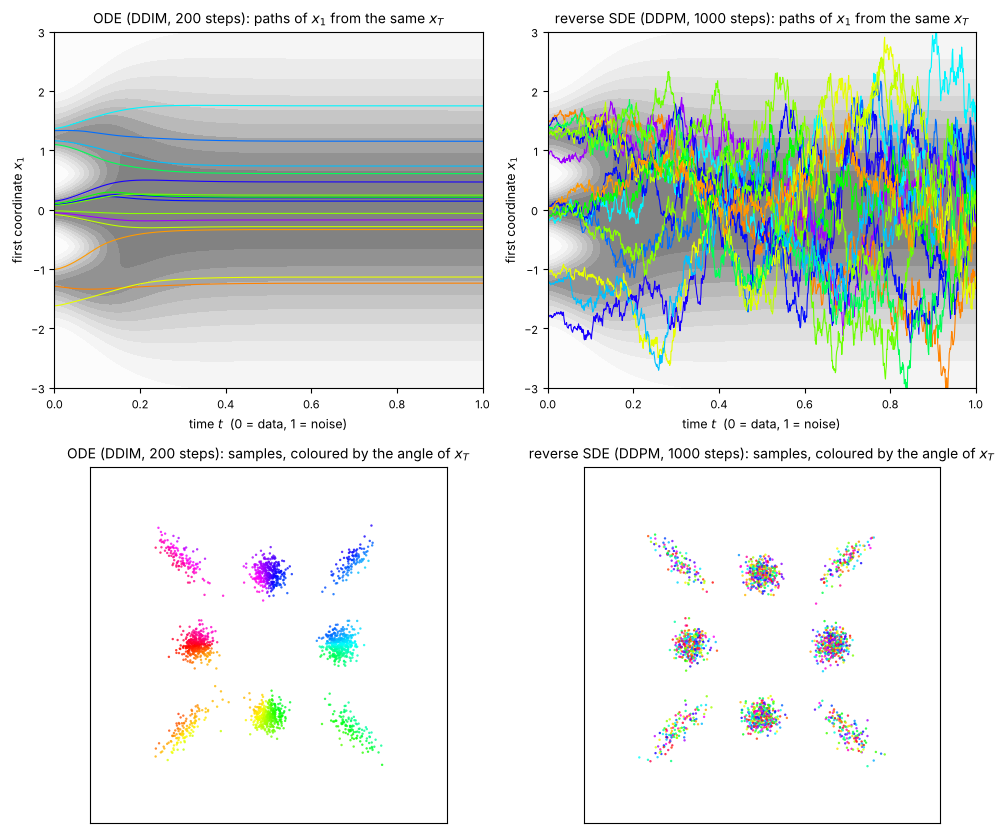

In [16]:
N_SHOW = 15
angle = torch.atan2(x_T_traj[:, 1], x_T_traj[:, 0]).numpy()   # colour code: direction of the starting noise
fig, axes = plt.subplots(2, 2, figsize=(10, 8.4))
for col, (name, traj, grid) in enumerate([("ODE (DDIM, 200 steps)", ode_traj, grid_ode),
                                          ("reverse SDE (DDPM, 1000 steps)", sde_traj, grid_sde)]):
    ax = axes[0, col]
    show_density_tx(ax)
    for i in range(N_SHOW):
        ax.plot(grid, traj[:, i, 0].numpy(), lw=0.8, color=plt.get_cmap("hsv")((angle[i] + np.pi) / (2 * np.pi)))
    ax.set_title(f"{name}: paths of $x_1$ from the same $x_T$")
    ax = axes[1, col]
    ax.scatter(traj[-1, :, 0], traj[-1, :, 1], c=angle, cmap="hsv", s=3, alpha=0.8, linewidths=0)
    ax.set(xlim=(-LIM, LIM), ylim=(-LIM, LIM), aspect="equal", xticks=[], yticks=[],
           title=f"{name}: samples, coloured by the angle of $x_T$")
plt.tight_layout()
plt.show()

The ODE paths (top left) are smooth. They barely move while $t\gtrsim0.5$ and then glide into a mode. The SDE paths (top
right) jitter all the way down, yet the printed check shows that both clouds have the same marginal $q_t$ at every time.
The bottom row shows the difference that matters. The ODE is a **smooth, deterministic map** from noise to data:
neighbouring noise vectors land next to each other, so the colours form coherent regions, and each mode receives a
contiguous wedge of noise space. That map is invertible (run the ODE backwards), so it is a **continuous normalising
flow** (Chen et al. 2018). Notebook 08 trains such flows directly. The SDE forgets where it started: the colours are mixed.

### 4.1 Why bother with noise? The SDE forgets errors

In §1.2 we saw that reverse SDE = ODE + Langevin dynamics targeting $p_t$. Langevin dynamics pulls *any* distribution
towards $p_t$, so the SDE should **repair** errors in the state that the ODE would faithfully transport to the output.
To isolate this, we take *exact* samples of $q_{t_p}$, corrupt them (scale by 1.3, an over-dispersed state like a bad
step or an imperfect denoiser would produce), and continue with exact scores from $t_p$ down to 0.

In [17]:
PERT_TIMES = [0.9, 0.7, 0.5, 0.35, 0.2, 0.1, 0.05]
x0_p = gmm.sample(N_EVAL, generator=torch.Generator().manual_seed(31)).double()
z_p = torch.randn(N_EVAL, 2, generator=torch.Generator().manual_seed(32), dtype=torch.float64)
pert = {"ODE (DDIM)": [], "SDE (DDPM)": [], "no corruption": []}
outputs_at = {}
for tp in PERT_TIMES:
    ab = abar_fn(tp)
    x_tp = math.sqrt(ab) * x0_p + math.sqrt(1 - ab) * z_p           # exact samples of q_tp ...
    grid = np.concatenate([np.linspace(tp, T_MIN, 200), [0.0]])
    out_ode = ddim_sampler(eps_exact, 1.3 * x_tp, grid)              # ... corrupted, then denoised
    out_sde = ddpm_sampler(eps_exact, 1.3 * x_tp, grid, gen=torch.Generator().manual_seed(33))
    pert["ODE (DDIM)"].append(quality(out_ode)[1])
    pert["SDE (DDPM)"].append(quality(out_sde)[1])
    pert["no corruption"].append(quality(ddim_sampler(eps_exact, x_tp, grid))[1])
    outputs_at[tp] = (out_ode, out_sde)
for k, v in pert.items():
    print(f"{k:14s} sliced W1: " + "  ".join(f"t_p={tp}: {e:.3f}" for tp, e in zip(PERT_TIMES, v)))

ODE (DDIM)     sliced W1: t_p=0.9: 0.127  t_p=0.7: 0.133  t_p=0.5: 0.133  t_p=0.35: 0.133  t_p=0.2: 0.155  t_p=0.1: 0.166  t_p=0.05: 0.207
SDE (DDPM)     sliced W1: t_p=0.9: 0.037  t_p=0.7: 0.028  t_p=0.5: 0.028  t_p=0.35: 0.050  t_p=0.2: 0.093  t_p=0.1: 0.113  t_p=0.05: 0.157
no corruption  sliced W1: t_p=0.9: 0.031  t_p=0.7: 0.031  t_p=0.5: 0.023  t_p=0.35: 0.023  t_p=0.2: 0.028  t_p=0.1: 0.028  t_p=0.05: 0.028


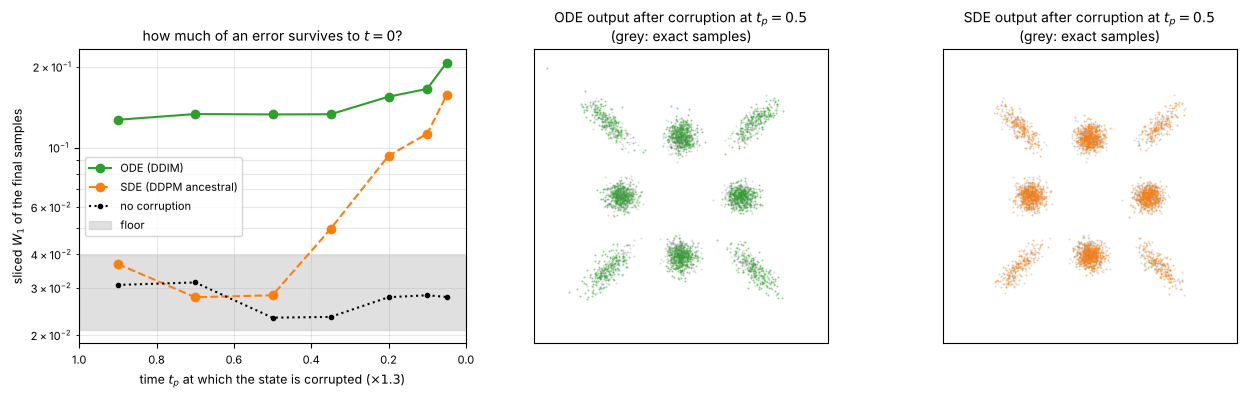

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ax = axes[0]
ax.semilogy(PERT_TIMES, pert["ODE (DDIM)"], "o-", color=COL["DDIM"], label="ODE (DDIM)")
ax.semilogy(PERT_TIMES, pert["SDE (DDPM)"], "o--", color=COL["DDPM ancestral"], label="SDE (DDPM ancestral)")
ax.semilogy(PERT_TIMES, pert["no corruption"], "o:", color="k", ms=3, label="no corruption")
ax.axhspan(floor[:, 1].mean() - 2 * floor[:, 1].std(), floor[:, 1].mean() + 2 * floor[:, 1].std(), color=COL["floor"],
           alpha=0.6, label="floor")
ax.set(xlabel=r"time $t_p$ at which the state is corrupted ($\times1.3$)", ylabel="sliced $W_1$ of the final samples",
       title="how much of an error survives to $t=0$?", xlim=(1, 0))
ax.grid(alpha=0.3, which="both")
ax.legend()
tp_show = 0.5
for ax, (name, x, c) in zip(axes[1:], [("ODE", outputs_at[tp_show][0], COL["DDIM"]),
                                       ("SDE", outputs_at[tp_show][1], COL["DDPM ancestral"])]):
    dm.scatter2d(x_true, ax=ax, s=2, alpha=0.25, c=COL["data"], lim=LIM)
    dm.scatter2d(x, ax=ax, s=2, alpha=0.5, c=c, lim=LIM, title=f"{name} output after corruption at $t_p={tp_show}$\n(grey: exact samples)")
plt.tight_layout()
plt.show()

The ODE transports the corruption, whenever it happens, straight into the output: the samples are too spread out. The
SDE **erases** errors made at high noise. There the Langevin part runs at rate
$\beta(t)/2$, which is large, and $p_t$ is nearly Gaussian, so the chain mixes fast. Errors made late, at low noise, have
no time to be corrected. This is the real reason to keep some stochasticity: with an imperfect network and a generous
budget, a stochastic sampler can beat a deterministic one (Karras et al. 2022 add a tunable amount of "churn" for
this). We test it on a trained network in §8.

## 5 · DDIM inversion: from data back to noise

A deterministic ODE can be integrated **forwards** too: from data $x_0$ to its latent $x_T$. Swap the roles of $t$ and
$s$ in the DDIM update and step to *higher* noise:

$$x_s=\sqrt{a_s}\,\hat x_0(x_t,t)+\sqrt{1-a_s}\,\hat\epsilon(x_t,t),\qquad s>t .$$

**Why it is only approximate.** The sampler steps from $s$ down to $t$ using $\hat\epsilon(x_s,s)$, the prediction at the
*noisier* end. Inversion has not yet computed $x_s$, so it uses $\hat\epsilon(x_t,t)$ instead. The forward and backward
Euler steps use slopes from opposite ends of the interval, so they do not cancel. The mismatch per step is
$O(h^2)$, and the round trip (invert, then sample) has an $O(h)$ error. It vanishes as the steps shrink, or wherever
$\hat\epsilon$ is constant along the path.

**Why it matters.** Inversion gives every real data point a latent code that the sampler maps back to it. Editing
methods (notebook 07) invert an image, change something (the prompt, the guidance, part of the latent) and sample again,
so that everything not edited is preserved.

In [19]:
@torch.no_grad()
def ddim_invert(eps_fn, x0, ts_up, *, abar=abar_fn):
    """Deterministic DDIM run forwards in time (data -> noise) on the ascending grid ts_up = [0, t_1, ..., 1].

    eps is evaluated at the current, less noisy point: the approximation discussed in the text."""
    x = x0
    for t, s in zip(ts_up[:-1], ts_up[1:]):
        a_t, a_s = abar(t), abar(s)
        eps = eps_fn(x, max(t, ts_up[1]))     # the network never saw t = 0: use the first grid time instead
        x0_hat = (x - math.sqrt(1 - a_t) * eps) / math.sqrt(a_t)
        x = math.sqrt(a_s) * x0_hat + math.sqrt(1 - a_s) * eps
    return x


# CHECK: our inversion reproduces dm.ddim_invert on the discrete schedule
x0_inv32 = gmm.sample(300, generator=torch.Generator().manual_seed(41))
for n in (10, 50):
    ours = ddim_invert(eps_disc, x0_inv32, disc_grid(n)[::-1], abar=abar_disc)
    theirs = dm.ddim_invert(exact_model, sched, x0_inv32, n_steps=n)
    print(f"CHECK ddim_invert == dm.ddim_invert ({n} steps): max |diff| = {(ours - theirs).abs().max():.1e}")
    assert torch.allclose(ours, theirs, atol=1e-4)

# Round trip: invert with n steps, then sample back with the same n steps
x0_inv, lab_inv = gmm.sample(N_EVAL, return_labels=True, generator=torch.Generator().manual_seed(42))
x0_inv = x0_inv.double()
INV_STEPS = [5, 10, 20, 50, 100, 250, 1000]
roundtrip = []
for n in INV_STEPS:
    z_inv = ddim_invert(eps_exact, x0_inv, uniform_grid(n)[::-1])
    x_back = ddim_sampler(eps_exact, z_inv, uniform_grid(n))
    roundtrip.append((x_back - x0_inv).norm(dim=1).mean().item())
    if n == 1000:
        z_accurate = z_inv
print("round-trip error (mean ||x0 - sample(invert(x0))||): "
      + ", ".join(f"{n} steps {e:.1e}" for n, e in zip(INV_STEPS, roundtrip)))
# CHECK: the ODE pushes the data distribution onto N(0, I)
cov = torch.cov(z_accurate.T)
print(f"latents of {N_EVAL} data points: mean {z_accurate.mean(0).numpy().round(3)}, covariance {cov.numpy().round(3).tolist()}")

CHECK ddim_invert == dm.ddim_invert (10 steps): max |diff| = 4.8e-07
CHECK ddim_invert == dm.ddim_invert (50 steps): max |diff| = 1.9e-06


round-trip error (mean ||x0 - sample(invert(x0))||): 5 steps 7.6e-01, 10 steps 2.5e-01, 20 steps 1.4e-01, 50 steps 6.2e-02, 100 steps 3.2e-02, 250 steps 1.3e-02, 1000 steps 3.7e-03
latents of 2000 data points: mean [-0.003  0.017], covariance [[0.982, -0.015], [-0.015, 0.984]]


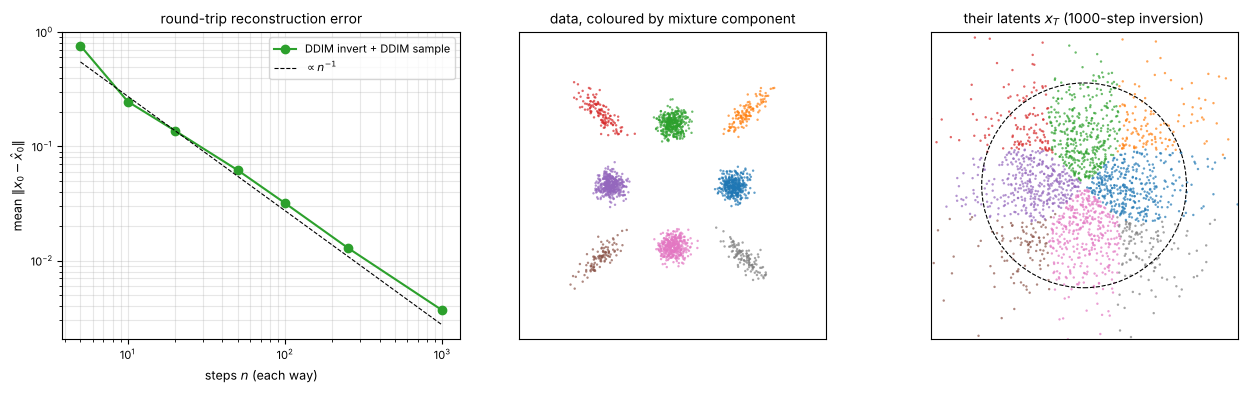

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ax = axes[0]
ax.loglog(INV_STEPS, roundtrip, "o-", color=COL["DDIM"], label="DDIM invert + DDIM sample")
ax.loglog(INV_STEPS, roundtrip[2] * (np.array(INV_STEPS) / INV_STEPS[2]) ** -1.0, "k--", lw=0.8, label=r"$\propto n^{-1}$")
ax.set(xlabel="steps $n$ (each way)", ylabel=r"mean $\|x_0-\hat x_0\|$", title="round-trip reconstruction error")
ax.grid(alpha=0.3, which="both")
ax.legend()
comp_cmap = plt.get_cmap("tab10")
dm.scatter2d(x0_inv, ax=axes[1], s=3, alpha=0.7, c=comp_cmap(lab_inv.numpy()), lim=LIM,
             title="data, coloured by mixture component")
dm.scatter2d(z_accurate, ax=axes[2], s=3, alpha=0.7, c=comp_cmap(lab_inv.numpy()), lim=LIM,
             title="their latents $x_T$ (1000-step inversion)")
axes[2].add_patch(plt.Circle((0, 0), 2.0, fill=False, ls="--", color="k", lw=0.8))
plt.tight_layout()
plt.show()

The round-trip error falls like $1/n$, as the Euler-type argument predicts. With exact scores it is tiny at a few
hundred steps. In practice, with a network, editing pipelines use about 50 steps and accept a small reconstruction
error. Some methods remove it with fixed-point iterations (Exercise 4) or by optimising the guidance's null embedding.

On the right, the ODE turns the mixture into a standard Gaussian (the printed mean and covariance are close to $0$ and
$I$; the dashed circle has radius 2). Each component owns a **region** of latent space whose Gaussian mass equals its
mixture weight. This is the inverse of the bottom-left panel of §4: the heavy inner components get wedges near the
middle and the light outer ones get the outskirts.

## 6 · Where to put the steps: uniform in $t$ vs Karras (EDM) spacing

The ODE is fixed, but the grid $t_0>\dots>t_n$ is ours to choose. Karras et al. (2022) work directly in the
$(\tilde x,\sigma)$ variables of §3.2. They use Heun's method on $d\tilde x/d\sigma=(\tilde x-D(\tilde x;\sigma))/\sigma$,
with $D(\tilde x;\sigma)=\tilde x+\sigma^2\nabla\log p_\sigma(\tilde x)$ (Tweedie in VE form), and a polynomial spacing in
$\sigma$:

$$\sigma_i=\Big(\sigma_{\max}^{1/\rho}+\tfrac{i}{N-1}\big(\sigma_{\min}^{1/\rho}-\sigma_{\max}^{1/\rho}\big)\Big)^{\rho},\quad i=0,\dots,N-1,\qquad\sigma_N=0 .$$

$\rho=1$ is uniform in $\sigma$, $\rho\to\infty$ is uniform in $\log\sigma$, and EDM's default $\rho=7$ sits in between,
with more steps at low noise. We keep our process's own $\sigma_{\max}=\sigma(1)$ and $\sigma_{\min}=\sigma(t_{\min})$, so
every sampler starts from the same $x_T$ and only the spacing differs. First we check that the VE denoiser built from our
VP noise predictor equals Tweedie's formula applied to the VE-noised mixture (`gmm.noised_ve`).

In [21]:
def denoiser(eps_fn, xt, sig):
    """D(x~; sigma) = x~ - sigma * eps_hat: the posterior-mean denoiser in the VE variables x~ = x / sqrt(abar)."""
    return xt - sig * eps_fn(xt / math.sqrt(1 + sig ** 2), t_of_sigma(sig))


# CHECK: D from the VP eps-predictor == VE Tweedie x~ + sigma^2 grad log p_sigma(x~), with p_sigma = gmm.noised_ve(sigma)
for sig in (0.05, 0.5, 5.0):
    xt_chk = gmm.noised_ve(sig).sample(500, generator=torch.Generator().manual_seed(51)).double()
    d_vp = denoiser(eps_exact, xt_chk, sig)
    d_ve = xt_chk + sig ** 2 * gmm.noised_ve(sig).score(xt_chk)
    print(f"CHECK sigma = {sig}: max |D_VP - D_VE| = {(d_vp - d_ve).abs().max():.1e}")
    assert torch.allclose(d_vp, d_ve, atol=1e-8)


def karras_sigmas(n, rho=7.0, s_max=SIGMA_MAX, s_min=SIGMA_MIN):
    """EDM's n noise levels (descending, s_max ... s_min), followed by 0."""
    i = np.arange(n)
    s = (s_max ** (1 / rho) + i / (n - 1) * (s_min ** (1 / rho) - s_max ** (1 / rho))) ** rho
    return np.concatenate([s, [0.0]])


@torch.no_grad()
def heun_sigma_sampler(eps_fn, x, sigmas, *, return_traj=False):
    """EDM's deterministic sampler (Karras et al. 2022, Alg. 1): Heun on dx~/dsigma = (x~ - D) / sigma.

    Input/output in VP units; Euler on the final step to sigma = 0, so n steps cost 2n - 1 NFE."""
    xt = x * math.sqrt(1 + sigmas[0] ** 2)
    traj = [x]
    for s_t, s_s in zip(sigmas[:-1], sigmas[1:]):
        d = (xt - denoiser(eps_fn, xt, s_t)) / s_t
        x_pred = xt + (s_s - s_t) * d
        if s_s > 0:
            d2 = (x_pred - denoiser(eps_fn, x_pred, s_s)) / s_s
            xt = xt + (s_s - s_t) * 0.5 * (d + d2)
        else:
            xt = x_pred
        traj.append(xt / math.sqrt(1 + s_s ** 2))
    return traj if return_traj else traj[-1]


GRIDS = {"uniform in $t$": lambda n: sigmas_of_times(uniform_grid(n)),
         r"Karras $\rho=7$": lambda n: karras_sigmas(n, 7.0),
         r"uniform in $\sigma$ ($\rho=1$)": lambda n: karras_sigmas(n, 1.0)}
GRID_COL = dict(zip(GRIDS, ["tab:blue", "tab:green", "tab:brown"]))


def plain(label):
    """A LaTeX legend label as plain text, for printing."""
    return label.replace("$", "").replace("\\rho", "rho").replace("\\sigma", "sigma")


NFES_6 = [5, 10, 20, 50, 100, 250]
spacing = {}
t0 = time.time()
for gname, gfun in GRIDS.items():
    for solver in ("Euler = DDIM", "Heun"):
        rows = []
        for nfe in NFES_6:
            if solver == "Heun":
                n = (nfe + 1) // 2
                traj = heun_sigma_sampler(eps_exact, x_T, gfun(n), return_traj=True)
                used = 2 * n - 1
            else:
                traj = euler_sigma_sampler(eps_exact, x_T, gfun(nfe), return_traj=True)
                used = nfe
            rows.append(dict(nfe=used, sw=quality(traj[-1])[1], path=(traj[-2][:N_PATH] - x_ref_tmin).norm(dim=1).mean().item()))
        spacing[(gname, solver)] = rows
print(f"spacing sweep in {time.time() - t0:.0f} s")
for (gname, solver), rows in spacing.items():
    print(f"{plain(gname):24s} {solver:13s} sliced W1: " + " ".join(f"{r['sw']:.3f}" for r in rows))

CHECK sigma = 0.05: max |D_VP - D_VE| = 4.4e-16
CHECK sigma = 0.5: max |D_VP - D_VE| = 8.9e-16
CHECK sigma = 5.0: max |D_VP - D_VE| = 1.1e-14


spacing sweep in 41 s
uniform in t             Euler = DDIM  sliced W1: 0.320 0.102 0.054 0.037 0.035 0.034
uniform in t             Heun          sliced W1: 3.343 0.323 0.070 0.036 0.034 0.034
Karras rho=7             Euler = DDIM  sliced W1: 0.277 0.145 0.075 0.040 0.034 0.034
Karras rho=7             Heun          sliced W1: 2.841 1.391 0.147 0.039 0.035 0.034
uniform in sigma (rho=1) Euler = DDIM  sliced W1: 0.860 0.832 0.777 0.623 0.426 0.168
uniform in sigma (rho=1) Heun          sliced W1: 31.038 15.455 6.643 2.193 0.834 0.189


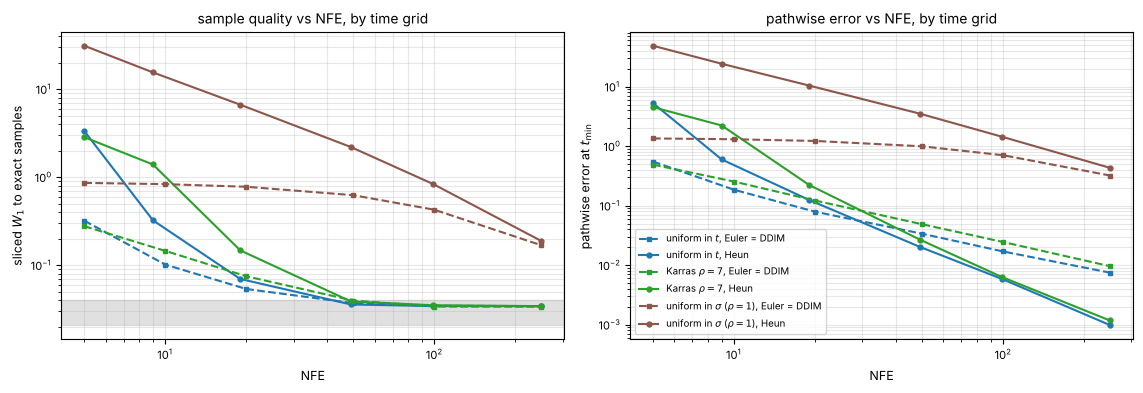

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for (gname, solver), rows in spacing.items():
    for ax, key in zip(axes, ("sw", "path")):
        ax.loglog([r["nfe"] for r in rows], [r[key] for r in rows], "o-" if solver == "Heun" else "s--", ms=3.5,
                  color=GRID_COL[gname], label=f"{gname}, {solver}")
axes[0].axhspan(floor[:, 1].mean() - 2 * floor[:, 1].std(), floor[:, 1].mean() + 2 * floor[:, 1].std(),
                color=COL["floor"], alpha=0.6)
axes[0].set(xlabel="NFE", ylabel="sliced $W_1$ to exact samples", title="sample quality vs NFE, by time grid")
axes[1].set(xlabel="NFE", ylabel=r"pathwise error at $t_{\min}$", title="pathwise error vs NFE, by time grid")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Spacing matters a lot.** Uniform-in-$\sigma$ is a disaster at every budget we tried: it spends almost all of its steps
at enormous noise levels where nothing happens. Between the two sensible grids, though, the outcome is less clear-cut than
EDM's reputation suggests. On this toy, uniform-in-$t$ (for the linear VP schedule) is about as good as Karras $\rho=7$,
and often a bit better at small budgets, for both solvers. To understand why, measure **where the solver makes its
errors**. Starting from exact states along the reference trajectories, take one step of fixed size in $\log\sigma$ and
compare with the exact result. Measured in VP units, this local error density shows how much each region of noise
levels deserves steps.

In [23]:
N_PROF, SUB = 40, (10 if FAST else 50)
prof_sig = np.exp(np.linspace(math.log(SIGMA_MAX), math.log(SIGMA_MIN), N_PROF + 1))
x_state = x_T[:N_PATH].clone()            # exact states (VP units) at prof_sig, via fine Heun sub-steps
err_euler, err_heun = [], []
for s_t, s_s in zip(prof_sig[:-1], prof_sig[1:]):
    fine = np.exp(np.linspace(math.log(s_t), math.log(s_s), SUB + 1))
    x_next = heun_sigma_sampler(eps_exact, x_state, fine)
    one_euler = euler_sigma_sampler(eps_exact, x_state, np.array([s_t, s_s]))
    one_heun = heun_sigma_sampler(eps_exact, x_state, np.array([s_t, s_s]))
    err_euler.append((one_euler - x_next).norm(dim=1).mean().item())
    err_heun.append((one_heun - x_next).norm(dim=1).mean().item())
    x_state = x_next
err_euler, sig_mid = np.array(err_euler), np.sqrt(prof_sig[:-1] * prof_sig[1:])
hard = err_euler > 0.1 * err_euler.max()
hard_lo, hard_hi = sig_mid[hard].min(), sig_mid[hard].max()
print(f"'hard' region (local Euler error > 10% of its peak): sigma in [{hard_lo:.2f}, {hard_hi:.2f}]")
N_RUG = 15
for gname, gfun in GRIDS.items():
    s = gfun(N_RUG)[:-1]
    print(f"  {plain(gname):24s}: of its {N_RUG} noise levels {np.mean(s > hard_hi):4.0%} lie above, "
          f"{np.mean((s >= hard_lo) & (s <= hard_hi)):4.0%} inside, {np.mean(s < hard_lo):4.0%} below the hard region")

'hard' region (local Euler error > 10% of its peak): sigma in [0.10, 4.72]
  uniform in t            : of its 15 noise levels  47% lie above,  47% inside,   7% below the hard region
  Karras rho=7            : of its 15 noise levels  53% lie above,  33% inside,  13% below the hard region
  uniform in sigma (rho=1): of its 15 noise levels  93% lie above,   0% inside,   7% below the hard region


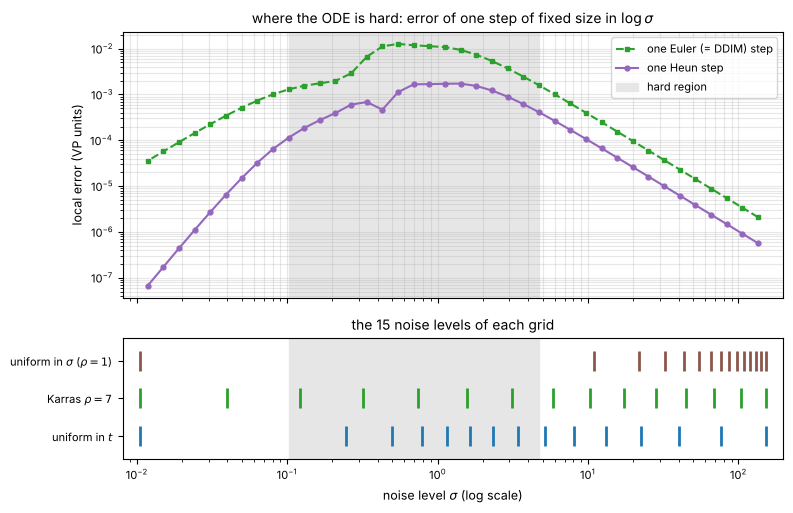

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
ax.loglog(sig_mid, err_euler, "s--", ms=3.5, color=COL["DDIM"], label="one Euler (= DDIM) step")
ax.loglog(sig_mid, err_heun, "o-", ms=3.5, color=COL["Heun ODE"], label="one Heun step")
ax.axvspan(hard_lo, hard_hi, color="0.9", zorder=0, label="hard region")
ax.set(ylabel="local error (VP units)", title=r"where the ODE is hard: error of one step of fixed size in $\log\sigma$")
ax.grid(alpha=0.3, which="both")
ax.legend()
ax = axes[1]
for j, (gname, gfun) in enumerate(GRIDS.items()):
    s = gfun(N_RUG)[:-1]
    ax.plot(s, np.full_like(s, j), "|", ms=14, mew=2, color=GRID_COL[gname])
ax.axvspan(hard_lo, hard_hi, color="0.9", zorder=0)
ax.set(yticks=range(len(GRIDS)), yticklabels=[g for g in GRIDS], ylim=(-0.6, len(GRIDS) - 0.4),
       xlabel=r"noise level $\sigma$ (log scale)", title=f"the {N_RUG} noise levels of each grid")
ax.set_xlim(SIGMA_MIN / 1.3, SIGMA_MAX * 1.3)
plt.tight_layout()
plt.show()

The solver's errors come from a band of noise levels around the scale of the data's structure (the same window in which
$\hat x_0$ moved in §3). Outside it, a step costs little accuracy. A good grid concentrates its steps in this band. The
printed fractions show that both sensible grids spend a large share of their steps *above* the band, where they are
nearly free. For our 2-D mixture, uniform-in-$t$ puts more of its steps inside the band, while $\rho=7$ puts more of
them above and below it. That is why uniform-in-$t$ does slightly better here.

The lesson is not "uniform-in-$t$ is better". **The right spacing depends on the range of scales present in the data.**
Natural images have structure at *every* scale, from the global layout down to pixel noise (their power spectrum is a
power law; see Dieleman's "Diffusion is spectral autoregression"). Their hard region therefore spans many decades of
$\sigma$, which is the regime $\rho=7$ was tuned for. EDM also lowers $\sigma_{\max}$ to 80, so that fewer steps are
wasted at the top (Exercise 3). When you move a diffusion model to a new data type, plotting this error profile is a
cheap way to choose a schedule.

> **Gotcha: start where your noise is.** The first grid point must be the noise level that $x_T$ actually has. Some
> widely used step selections ("leading" spacing) skip the last training timestep, so the sampler treats pure noise as if
> it were slightly less noisy. That causes visible artefacts, such as a restricted range of brightness, whenever
> $\bar\alpha_T$ is not tiny (Lin et al. 2024). Always
> include $t=T-1$ ("trailing" spacing). Our grids start exactly at $t=1$.

## 7 · Advanced (optional): exact log-likelihood from the probability-flow ODE

Because the ODE is a smooth bijection, it defines a density through the change-of-variables formula, as a normalising
flow does. Along a trajectory $x(t)$ of $\dot x=f(x,t)$, the continuity equation $\partial_tp+\nabla\!\cdot(fp)=0$ gives

$$\frac{d}{dt}\log p_t(x(t))=\partial_t\log p_t+f\cdot\nabla\log p_t=-\nabla\!\cdot f(x(t),t)
\quad\Longrightarrow\quad
\boxed{\;\log p_0(x_0)=\log p_1(x_1)+\int_0^1\nabla\!\cdot f(x(t),t)\,dt\;}$$

This is the **instantaneous change of variables** (Chen et al. 2018). To evaluate $\log p_0$ at a point $x_0$, integrate the
ODE *forwards* to $t=1$ while accumulating the divergence of the velocity, then add the log-density of the (Gaussian)
prior. In 2-D the divergence is the trace of a $2\times2$ Jacobian, which we compute exactly with autograd. In high
dimensions one uses Hutchinson's estimator $\nabla\!\cdot f\approx v^\top(\partial f/\partial x)v$ with random $v$
(FFJORD; Song et al. 2021). Near $t=0$ the velocity is stiff (the score of the narrow components is steep), so we space
the steps quadratically, $t_i=(i/n)^2$, and compare with a uniform grid.

In [25]:
def score_exact(x, t):
    """Exact score of q_t (works at t = 0 too: q_0 is the data mixture)."""
    return gmm.noised(abar_fn(t)).score(x)


def velocity_and_divergence(x, t, score_fn=score_exact):
    """PF-ODE velocity f(x, t) and its divergence (exact trace of the 2x2 Jacobian, by autograd)."""
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        f = -0.5 * beta_fn(t) * (x + score_fn(x, t))
        div = sum(torch.autograd.grad(f[:, i].sum(), x, retain_graph=True)[0][:, i] for i in range(x.shape[1]))
    return f.detach(), div.detach()


def ode_log_likelihood(x0, ts, score_fn=score_exact):
    """log p_{ts[0]}(x0): integrate x and the divergence forwards to t = ts[-1] = 1 with Heun's method on the grid ts."""
    x, div_int = x0.clone(), torch.zeros(x0.shape[0], dtype=x0.dtype)
    for t, s in zip(ts[:-1], ts[1:]):
        f1, d1 = velocity_and_divergence(x, t, score_fn)
        f2, d2 = velocity_and_divergence(x + (s - t) * f1, s, score_fn)
        x = x + (s - t) * 0.5 * (f1 + f2)
        div_int = div_int + (s - t) * 0.5 * (d1 + d2)
    log_prior_exact = gmm.noised(abar_fn(ts[-1])).log_prob(x).double()           # the exact q_1
    log_prior_gauss = -0.5 * (x ** 2).sum(1) - x.shape[1] / 2 * math.log(2 * math.pi)   # what you'd use in practice
    return log_prior_exact + div_int, log_prior_gauss + div_int


pts = torch.cat([gmm.sample(6, generator=torch.Generator().manual_seed(61)).double(),
                 torch.tensor([[0.0, 0.0], [1.0, 1.0]], dtype=torch.float64)])   # 6 data points + 2 between the modes
true_lp = gmm.log_prob(pts).double()
LL_STEPS = [25, 100] if FAST else [25, 100, 400, 1600]
ll_err = {"uniform $t_i=i/n$": [], "quadratic $t_i=(i/n)^2$": []}
t0 = time.time()
for n in LL_STEPS:
    u = np.linspace(0, 1, n + 1)
    for name, ts in zip(ll_err, (u, u ** 2)):
        est, est_gauss = ode_log_likelihood(pts, ts)
        ll_err[name].append((est - true_lp).abs().max().item())
print(f"likelihood runs in {time.time() - t0:.0f} s")
print(f"{'point':>16s} {'true log p':>11s} {'ODE estimate':>13s} {'(N(0,I) prior)':>15s}")
for p, tl, e, eg in zip(pts, true_lp, est, est_gauss):
    print(f"({p[0]:6.2f},{p[1]:6.2f}) {tl:11.4f} {e:13.4f} {eg:15.4f}")
print(f"max |error| with {LL_STEPS[-1]} quadratic steps: {(est - true_lp).abs().max():.1e}")
assert (est - true_lp).abs().max() < (0.05 if FAST else 1e-3)

likelihood runs in 10 s
           point  true log p  ODE estimate  (N(0,I) prior)
( -1.25, -0.05)      0.2936        0.2936          0.2936
(  0.03,  1.29)      0.1587        0.1587          0.1587
(  0.02, -1.06)     -0.0773       -0.0773         -0.0773
(  1.03,  0.15)     -0.9235       -0.9235         -0.9235
(  1.21, -0.04)      0.3662        0.3662          0.3662
(  0.18,  1.16)     -0.4800       -0.4800         -0.4800
(  0.00,  0.00)    -24.6587      -24.6587        -24.6587
(  1.00,  1.00)     -3.1897       -3.1897         -3.1897
max |error| with 1600 quadratic steps: 5.5e-06


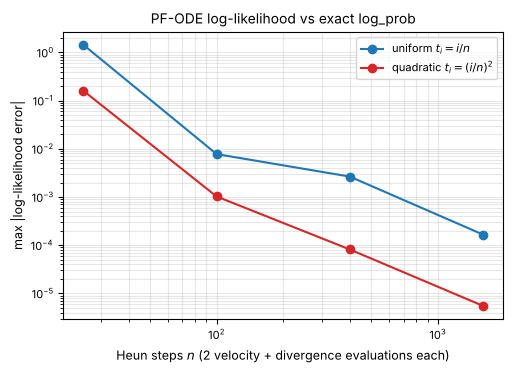

In [26]:
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for (name, errs), c in zip(ll_err.items(), ("tab:blue", "tab:red")):
    ax.loglog(LL_STEPS, errs, "o-", color=c, label=name)
ax.set(xlabel="Heun steps $n$ (2 velocity + divergence evaluations each)", ylabel="max |log-likelihood error|",
       title="PF-ODE log-likelihood vs exact log_prob")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

The ODE likelihood matches `dm.GaussianMixture.log_prob` to within a small fraction of a nat, including the two points
in the low-density gaps between modes. Putting the steps where the ODE is stiff (quadratic spacing near $t=0$) is
worth more than an order of magnitude in accuracy at the same cost: the lesson of §6 again. Replacing the exact $q_1$ by
$\mathcal N(0,I)$ changes nothing visible, since $\bar\alpha(1)$ is tiny. With a trained network the same procedure gives
the *model's* exact likelihood (Exercise 5). This is how diffusion models report bits-per-dimension, and it is
deterministic, unlike the ELBO of notebook 02.

## 8 · With a trained network: model error sets a floor

So far the vector field was perfect. Now we train an $\epsilon$-network exactly as in notebook 03 (`dm.MLPDenoiser`,
`dm.train_diffusion`, linear schedule, $T=1000$) and repeat a reduced NFE sweep. Using exact scores, we can split the
error into two parts: **discretisation error** (the exact-score curves of §2) and **model error** (the extra error of
the trained network).

> **Gotcha: feed the network the noise level it was trained on.** The network was trained on the *discrete*
> $\bar\alpha_k$, while our samplers use the continuous $\bar\alpha(t)$ at arbitrary times (the two differ slightly, §1.1).
> The correct conditioning input is the (fractional) index $k^*$ whose training noise level equals the sampler's,
> $\bar\alpha_{k^*}=\bar\alpha(t)$, not the clock time $tT-1$. The MLP's sinusoidal time embedding accepts fractional
> inputs and interpolates smoothly. Libraries such as `k-diffusion` and `diffusers`' Karras schedulers convert $\sigma$
> to a timestep in exactly this way.

In [27]:
dm.seed_everything(0)
train_data = gmm.sample(20_000, generator=torch.Generator().manual_seed(71))
sched_dev = dm.NoiseSchedule(T, "linear", device=device)
net = dm.MLPDenoiser(data_dim=2, hidden=128)
out = dm.train_diffusion(net, train_data, sched_dev, steps=TRAIN_STEPS, batch_size=256, lr=1e-3, device=device,
                         progress=False, log_every=max(TRAIN_STEPS // 4, 1))
ema_net = out["ema"].model.eval()                   # sample with the EMA weights (notebook 02)
print(f"{dm.count_params(net) / 1e3:.0f}k parameters, trained in {out['seconds']:.0f} s")

NEG_LOG_AB = -np.log(AB_DISC)                       # increasing in k


def noise_matched_index(t):
    """Fractional network index k* whose training noise level alpha_bar_{k*} equals abar_fn(t)."""
    return float(np.interp(-math.log(abar_fn(t)), NEG_LOG_AB, np.arange(T)))


@torch.no_grad()
def net_eps(x, t):
    """The trained network as an eps_fn(x, t): float64 CPU state in, float64 CPU prediction out."""
    k = torch.full((x.shape[0],), noise_matched_index(t), device=device)
    return ema_net(x.float().to(device), k).double().cpu()


# CHECK: at the network's own noise levels the conversion returns the integer index
ks = np.array([0, 10, 250, 500, 999])
k_back = np.array([float(np.interp(NEG_LOG_AB[k], NEG_LOG_AB, np.arange(T))) for k in ks])
assert np.allclose(k_back, ks)
print("clock-time index k  ->  noise-matched index k* at t = (k+1)/T:  "
      + ", ".join(f"{k} -> {noise_matched_index((k + 1) / T):.1f}" for k in ks))

step   1000 | loss 0.2778


step   2000 | loss 0.2341


step   3000 | loss 0.2301


step   4000 | loss 0.2312
126k parameters, trained in 32 s
clock-time index k  ->  noise-matched index k* at t = (k+1)/T:  0 -> 0.1, 10 -> 10.3, 250 -> 250.1, 500 -> 499.4, 999 -> 995.6


In [28]:
NFES_8 = [5, 10, 20, 50, 100, 250]
NAMES_8 = ["DDPM ancestral", "Heun ODE", "DDIM"]
t0 = time.time()
sweep_net = nfe_sweep(net_eps, x_T, NAMES_8, NFES_8)
print(f"trained-network sweep in {time.time() - t0:.0f} s")
for name, rows in sweep_net.items():
    print(f"{name:16s} sliced W1: " + " ".join(f"{r['sw']:.3f}" for r in rows)
          + "   (exact score: " + " ".join(f"{r['sw']:.3f}" for r in sweep[name][:len(NFES_8)]) + ")")

trained-network sweep in 50 s
DDPM ancestral   sliced W1: 0.354 0.140 0.080 0.045 0.036 0.036   (exact score: 0.354 0.134 0.076 0.045 0.034 0.031)
Heun ODE         sliced W1: 0.150 0.131 0.057 0.047 0.048 0.049   (exact score: 0.085 0.098 0.047 0.034 0.034 0.034)
DDIM             sliced W1: 0.295 0.104 0.060 0.049 0.048 0.048   (exact score: 0.320 0.102 0.054 0.037 0.035 0.034)


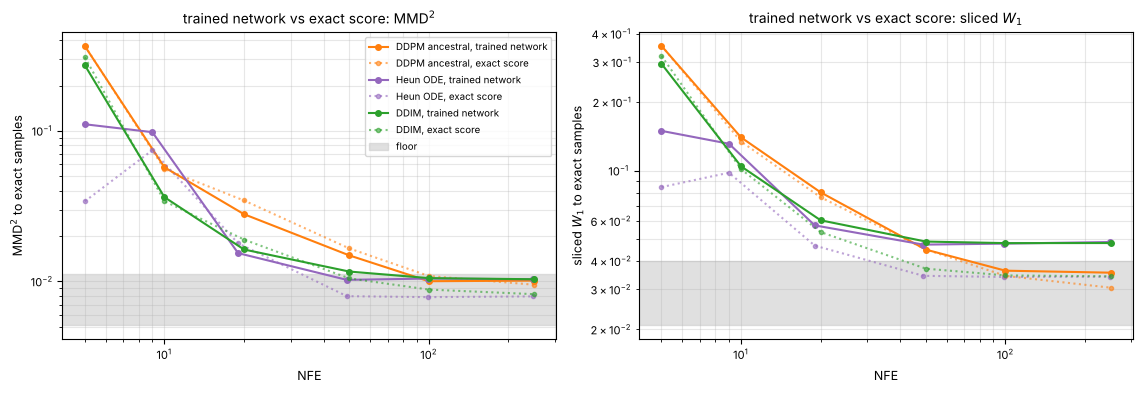

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, (j, key, label) in zip(axes, [(0, "mmd", "MMD$^2$"), (1, "sw", "sliced $W_1$")]):
    for name in NAMES_8:
        ax.loglog([r["nfe"] for r in sweep_net[name]], [r[key] for r in sweep_net[name]], "o-", ms=4,
                  color=COL[name], label=f"{name}, trained network")
        ax.loglog([r["nfe"] for r in sweep[name][:len(NFES_8)]], [r[key] for r in sweep[name][:len(NFES_8)]], "o:",
                  ms=3, color=COL[name], alpha=0.6, label=f"{name}, exact score")
    lo, hi = floor[:, j].mean() - 2 * floor[:, j].std(), floor[:, j].mean() + 2 * floor[:, j].std()
    ax.axhspan(max(lo, 1e-6), hi, color=COL["floor"], alpha=0.6, label="floor")
    ax.set(xlabel="NFE", ylabel=f"{label} to exact samples", title=f"trained network vs exact score: {label}")
    ax.grid(alpha=0.3, which="both")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

At small NFE the trained-network curves (solid) stay close to the exact-score curves (dotted). Discretisation error
dominates there, and the choice of sampler matters as much as before. As the budget grows, the exact-score curves
fall to the floor, but the deterministic samplers driven by the trained network **level off** above them. More steps
solve the network's ODE more accurately, but that ODE belongs to a slightly wrong vector field. The remaining gap is
**model error**, and no ODE solver can remove it.

DDPM behaves differently. Its curve keeps falling and typically ends up much closer to its exact-score counterpart (see
the printout). This is §4.1 at work: the Langevin part of the reverse SDE keeps pulling the samples back towards the
marginals, which partially corrects the network's systematic errors. The trade-off is clear: at small budgets
deterministic samplers win, while at large budgets with an imperfect model, some stochasticity pays (Exercise 1). For
ODE samplers, **you only need enough steps to get below the model-error floor**. Beyond that, extra NFE is wasted. This
is why well-trained image models are sampled with 20–50 DDIM-like steps, not 1000.

## 9 · Practical guidance

| goal | typical choice | NFE |
|---|---|---|
| reference quality, no time pressure | DDPM ancestral / Euler–Maruyama, or Heun with a little churn | 250–1000 |
| the robust default | DDIM ($\eta=0$) / Euler in $\sigma$, uniform-in-$t$ (trailing) or Karras spacing | 25–50 |
| best quality per NFE | multistep exponential-integrator solvers: DPM-Solver++(2M), UniPC; or EDM's Heun | 10–20 (Heun: ~35) |
| real-time | distilled or consistency models (progressive distillation, LCM, consistency models, adversarial distillation such as SDXL-Turbo) | 1–4 |
| editing / inversion / interpolation | deterministic ($\eta=0$) sampler and its inversion, so that noise ↔ data is a fixed map | 25–100 |

* **Count NFE, not steps or seconds per step.** The network evaluation dominates the cost. Heun costs 2 NFE per step.
  **Classifier-free guidance costs 2 NFE per step** (conditional + unconditional; notebook 06), so 50 guided DDIM steps
  cost 100 network passes (usually run as one doubled batch).
* **$\eta$ (stochasticity):** $\eta=0$ for few steps, for reproducibility, and for anything that needs inversion. Some
  noise ($\eta>0$, or EDM's churn) helps at large budgets when the model is imperfect (§4.1), but it needs more steps to
  pay off.
* **The last step** should return the denoised estimate $\hat x_0$ without adding noise. Never evaluate the network at
  $t=0$: it was never trained there.
* **$\hat x_0$ clipping** (to $[-1,1]$ for images, `clip_x0` in `dmtools`) and dynamic thresholding stop guided samplers
  from saturating. They change the update, though, so the sampler no longer solves the ODE and exact inversion breaks.
* **Precision:** keep schedule coefficients in float64. $1/\sqrt{\bar\alpha}$ reaches about 150 at $t=1$ here, and
  $1-\bar\alpha$ near $t=0$ loses digits in float32. bf16 is fine for the network itself.
* **Sample with EMA weights**, and pick the step count by checking where quality stops improving (§8). That plateau is
  the model's floor.

## Exercises

**Exercise 1 (the $\eta$ knob).** Run `ddim_sampler` with $\eta\in\{0,0.25,0.5,1\}$ at 20 and at 250 steps (exact score,
same `x_T`) and print `quality(...)`. Predict first: which $\eta$ wins at 20 steps, and which at 250? Then repeat with
`net_eps` instead of `eps_exact`.

<details><summary>Hint / solution</summary>

```python
for n in (20, 250):
    for eta in (0, 0.25, 0.5, 1):
        x = ddim_sampler(eps_exact, x_T, uniform_grid(n), eta=eta, gen=torch.Generator().manual_seed(0))
        print(n, eta, quality(x))
```
With 10–50 steps the DDPM-like $\eta=1$ is clearly the worst (as in §2). Small values ($\eta\lesssim0.5$) cost little and
are roughly as good as $\eta=0$. The differences between them are comparable to the seed-to-seed noise, so average over
a few seeds before concluding anything. At 250 steps every $\eta$ reaches the floor with exact scores. With the trained
network, compare with §8: at large budgets the injected noise can also correct model error (§4.1).
</details>

**Exercise 2 (make the toy image-like).** Images have many directions of tiny variance (fine detail). Embed the mixture
in 12-D with 10 extra coordinates of variance $10^{-6}$: `means = F.pad(gmm.means, (0, 10))`, and block-diagonal
covariances with `gmm.covs` in the top-left corner and `1e-6 * I` elsewhere. Build
`dm.GaussianMixture(gmm.weights, means, covs)` and its `exact_eps_fn`. Predict how Euler-in-$t$, Heun-in-$t$ and DDIM
behave in the extra coordinates, then measure the std of the generated samples there (true value 0.001) at 20 and 50 NFE.

<details><summary>Hint / solution</summary>

```python
import torch.nn.functional as F
d = 12
covs = torch.zeros(gmm.K, d, d, dtype=torch.float64); covs[:, :2, :2] = gmm.covs
covs[:, 2:, 2:] = 1e-6 * torch.eye(d - 2, dtype=torch.float64)
g12 = dm.GaussianMixture(gmm.weights, F.pad(gmm.means, (0, d - 2)), covs)
xT12 = torch.randn(2000, d, dtype=torch.float64)
for name in ["Euler ODE", "Heun ODE", "DDIM"]:
    n, _ = steps_for_nfe(name, 20)
    x = SAMPLERS[name][0](exact_eps_fn(g12), xT12, uniform_grid(n))
    print(name, x[:, 2:].std().item())   # true: 0.001
```
This is the stiffness of §3.2 in action. Euler-in-$t$ leaves residual noise about ten times the true std in every extra
direction, Heun-in-$t$ blows up, and DDIM adds no noise (it slightly over-smooths, with an absolute error below 0.001).
In the two "interesting" coordinates all three do about as well as before. Real images have thousands of such
directions, so the residual noise adds up to visible grain. This is why DDIM-style integrators replaced plain Euler.
</details>

**Exercise 3 (design a schedule).** The error profile in §6 says that the steps at very large $\sigma$ are nearly wasted.
Start EDM's Heun sampler at a smaller $\sigma_{\max}$ (EDM uses 80; try 80 and 20):
`heun_sigma_sampler(eps_exact, x_T, karras_sigmas(n, 7.0, s_max=20.0))`. The same unit-variance `x_T` works, because
the sampler takes its input in VP units and VP noise always has unit variance. Predict, then measure, the change in
sample quality at 10–20 NFE. How much error comes from treating $\sigma=20$ as "pure noise"?

<details><summary>Hint / solution</summary>

At $\sigma=20$ the data (std about 1.2) changes the noisy distribution's std by only about 0.2%, so treating it as pure noise
costs almost nothing. Every step saved at the top of the schedule goes into the hard region, so quality at 10–20 NFE
improves noticeably. You can go further: choose the $\sigma_i$ so that each step carries an equal share of the error
profile `err_heun` (cumulative sum, then invert by interpolation). This is a hand-made adaptive schedule.
</details>

**Exercise 4 (better inversion).** Improve `ddim_invert` with a fixed-point iteration. In each step, first compute
$x_s$ as now, then recompute $\hat\epsilon$ at $(x_s,s)$ and redo the step with it. Repeat 2–3 times. Plot the round-trip
error against $n$ as in §5. Predict: what happens to the $O(h)$ error?

<details><summary>Hint / solution</summary>

Inside the loop: `x_s = step(x, eps_fn(x, t))`, then `for _ in range(3): x_s = step(x, eps_fn(x_s, s))`. The update now
uses (an approximation of) the slope at the noisier end, which is what the sampler uses on the way back. Each
iteration shrinks the mismatch by a factor that gets smaller as the steps shrink: expect a few times lower error at
$n=5$ and well over an order of magnitude at $n=100$. Each iteration costs 1 NFE, and for very large steps the fixed-point
iteration need not converge.
</details>

**Exercise 5 (the model's likelihood).** Pass the trained network's score
$-\hat\epsilon_\theta(x,k^*)/\sqrt{1-\bar\alpha(t)}$ as `score_fn` to `ode_log_likelihood` in §7. The divergence needs
gradients through the network, so do not use `net_eps`, which runs under `torch.no_grad`. Start the grid at $t_{\min}$
rather than 0, since the network was never trained at $t=0$. Compare the model's log-likelihood with the truth,
`gmm.noised(abar_fn(T_MIN)).log_prob(pts)`, on the same 8 points. Where is the model most wrong?

<details><summary>Hint / solution</summary>

```python
def score_net(x, t):
    k = torch.full((x.shape[0],), noise_matched_index(t), device=device)
    return -ema_net(x.float().to(device), k).double().cpu() / math.sqrt(1 - abar_fn(t))
u = np.linspace(0, 1, 401)
est, _ = ode_log_likelihood(pts, T_MIN + (1 - T_MIN) * u ** 2, score_fn=score_net)
print(est - gmm.noised(abar_fn(T_MIN)).log_prob(pts).double())
```
On the data points the model's log-likelihood is typically within a few tenths of a nat of the truth. The two points
in the gaps between the modes are far worse. The network had almost no training signal there (notebook 03, §7), and
because the true density there is tiny, even a small error in the score translates into a large error in
$\log p$. Starting at $t_{\min}$ gives the likelihood of very slightly noised data, $q_{t_{\min}}$, which is standard.
</details>

## Key takeaways

* Sampling a diffusion model means **numerically solving a differential equation**. The DDPM chain is Euler–Maruyama
  for the reverse-time SDE $dx=[-\tfrac12\beta x-\beta\nabla\log p_t]dt+\sqrt\beta\,d\bar W$. The **probability-flow ODE**
  $\dot x=-\tfrac12\beta(x+\nabla\log p_t)$ has the same marginals, by Fokker–Planck.
* The **reverse SDE = ODE + Langevin corrector**. Its noise erases errors made at high noise levels, but it needs many
  steps. Deterministic solvers are far better per NFE at small budgets.
* **DDIM** follows from a non-Markovian forward process with DDPM's marginals, so it needs no retraining. With $\eta=0$
  it is **Euler's method in $(\tilde x=x/\sqrt{\bar\alpha},\ \sigma)$**: a convex step towards $\hat x_0$. It is exact when
  $\hat x_0$ is constant and it never overshoots. That stability, in data with many low-variance directions, is what
  makes it the robust default.
* Orders of convergence are real (Euler/DDIM $\propto$ NFE$^{-1}$, Heun $\propto$ NFE$^{-2}$) but only once steps are
  small. At very low NFE, *where* the steps go and *which variables* you integrate in matter more.
* The ODE is a **bijection** between noise and data, a continuous normalising flow. It gives DDIM **inversion** (an
  $O(h)$ approximation) and **exact likelihoods** via $\log p_0=\log p_1+\int\nabla\!\cdot f\,dt$.
* **Step spacing** should concentrate on the noise levels where the denoiser's output changes. That depends on the
  data's range of scales: Karras $\rho=7$ suits images, but on our toy uniform-in-$t$ does as well. Uniform-in-$\sigma$ is
  always bad.
* With a trained network, **model error sets a floor** for deterministic samplers. Use just enough NFE to reach it, and
  count NFE, including CFG's 2×. At large budgets, a stochastic sampler can partially correct model error.

## Further reading

* Song, Sohl-Dickstein, Kingma, Kumar, Ermon, Poole (2021). *Score-Based Generative Modeling through Stochastic Differential Equations.* ICLR. arXiv:2011.13456. The SDE/ODE view, predictor–corrector samplers, and likelihoods.
* Anderson (1982). *Reverse-time diffusion equation models.* Stochastic Processes and their Applications 12(3).
* Song, Meng, Ermon (2021). *Denoising Diffusion Implicit Models.* ICLR. arXiv:2010.02502.
* Karras, Aittala, Aila, Laine (2022). *Elucidating the Design Space of Diffusion-Based Generative Models* (EDM). NeurIPS. arXiv:2206.00364. The $(\tilde x,\sigma)$ view, Heun, $\rho$-spacing and churn.
* Lu, Zhou, Bao, Chen, Li, Zhu (2022). *DPM-Solver: A Fast ODE Solver for Diffusion Probabilistic Model Sampling in Around 10 Steps.* NeurIPS. arXiv:2206.00927; and *DPM-Solver++* (2022), arXiv:2211.01095.
* Nichol & Dhariwal (2021). *Improved Denoising Diffusion Probabilistic Models.* ICML. arXiv:2102.09672. Respacing the timesteps of a trained model.
* Lin, Liu, Li, Yang (2024). *Common Diffusion Noise Schedules and Sample Steps are Flawed.* WACV. arXiv:2305.08891. The "trailing" timestep gotcha.
* Chen, Rubanova, Bettencourt, Duvenaud (2018). *Neural Ordinary Differential Equations.* NeurIPS. arXiv:1806.07366; Grathwohl et al. (2019). *FFJORD.* ICLR. arXiv:1810.01367. The instantaneous change of variables and Hutchinson's trace estimator.
* Salimans & Ho (2022). *Progressive Distillation for Fast Sampling of Diffusion Models.* ICLR. arXiv:2202.00512; Song, Dhariwal, Chen, Sutskever (2023). *Consistency Models.* ICML. arXiv:2303.01469; Sauer, Lorenz, Blattmann, Rombach (2023). *Adversarial Diffusion Distillation.* arXiv:2311.17042. 1–4-step samplers.
* Sander Dieleman, *Diffusion is spectral autoregression* (sander.ai, 2024). Why images have structure at every noise level.
* Yang Song, *Generative Modeling by Estimating Gradients of the Data Distribution* (blog post, 2021). An accessible tour of the SDE view.